# Summary of Imaging Analyses Results

__This notebook merges all the imaging analyses results together and output, adding necessary QC steps.__

1. Extract the hits for cell-count differences;

2. Extract the hits for protein abundance changes;

3. Extract the hits for mislocalization.

In [1]:
import os
import polars as pl
import pandas as pd
import numpy as np
from tqdm import tqdm
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import umap
from functools import reduce
import operator
from adjustText import adjust_text
import sys
sys.path.append("../../../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../1_snakemake_pipeline/2025_varchamp_snakemake")
from img_utils import *
sys.path.append("../../..")
from analyses_plot_utils import *

sns.set_style(style='white')
sns.set_context("notebook", font_scale=.9)

In [2]:
ALLELE_COLLECTION_INFO = "../../../../1_allele_collection/3_outputs"
GFP_MISLOCAL_FEAT_STRICT, GFP_MISLOCAL_FEAT_LENIENT = "Altered_99th_perc_both_batches_GFP", "Altered_95th_perc_both_batches_GFP"

## 1. Loading Data

### 1.1 Metadata

In [3]:
# clin_var_df = pl.read_csv("../../../../3_integrated_assay_results/1_inputs/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=100000)
# clin_var_df

## old one
clin_var_df = pl.read_parquet(
    "../../../../1_allele_collection/3_outputs/VarChAMP_Allele_Collection_1Perc_ClinVar_dbNSFP_pLDDT_RSA_G2P_OMIM_MOI.parquet",
)

### 1.2 Imaging Analysis Results

Imaging QC results:

1 - Mutation and ORF fully captured in the read

2 - Mutation captured but not full ORF in the read; sequencing is still good, but the ORF is truncated;

3 - Wrong mutation captured but correct ORF

4 - Wrong ORF

5 - No reads

In [13]:
cell_count_summary = pl.read_csv(f"{CC_ABUND_DIR}/cell_count_diff_summary.csv").rename(
    {"Variant": "gene_allele"}
)
prot_abund_summary = pl.read_csv(f"{CC_ABUND_DIR}/prot_abundance_diff_summary.csv")
auroc_summary_df = pl.read_csv(f"/home/shenrunx/igvf/varchamp/2025_varchamp_snakemake/3.downstream_analyses/outputs/2.classification_results/imaging_analyses_classification_summary_one_perc.csv")
img_seq_qc_df = pl.read_csv(
    "../../1_inputs/seq_confirm_res/imaging_analyses_mislocalization_summary_clinvar_TT_update_20251107.csv",
)

## filter QC-failed alleles
## DUE TO FAILED WT reference sequences

## DUE TO sequence confirmation
alleles_to_drop = img_seq_qc_df.filter(
    pl.col("seq_result").is_not_null(),
    pl.col("seq_result").is_in([3,4])
).unique(["gene_allele"])["gene_allele"].to_list()

auroc_summary_df = auroc_summary_df.filter(
    ~pl.col("gene_allele").is_in(alleles_to_drop)
).sort("AUROC_Mean_GFP","gene_allele")
print(f"Misannotated alleles with 3,4:", len(alleles_to_drop))

auroc_summary_df

Misannotated alleles with 3,4: 39


symbol,gene_allele,Metadata_Bio_Batch,Altered_95th_perc_both_batches_GFP_ADJ,Altered_95th_perc_both_batches_GFP,Altered_95th_perc_both_batches_DNA,Altered_95th_perc_both_batches_Mito,Altered_95th_perc_both_batches_AGP,Altered_95th_perc_both_batches_Morph,Altered_99th_perc_both_batches_GFP_ADJ,Altered_99th_perc_both_batches_GFP,Altered_99th_perc_both_batches_DNA,Altered_99th_perc_both_batches_Mito,Altered_99th_perc_both_batches_AGP,Altered_99th_perc_both_batches_Morph,AUROC_Mean_GFP_ADJ,AUROC_Mean_GFP,AUROC_Mean_DNA,AUROC_Mean_Mito,AUROC_Mean_AGP,AUROC_Mean_Morph,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep1_GFP,AUROC_BioRep1_GFP_ADJ,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,AUROC_BioRep2_GFP,AUROC_BioRep2_GFP_ADJ
str,str,str,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""COMP""","""COMP_Ala171Thr""","""2024_01_Batch_7-8""",null,null,true,false,false,false,null,null,false,false,false,false,null,null,0.940087,0.969925,0.966711,0.95765,0.980054,0.978699,0.979818,0.975298,null,null,0.935247,0.954722,0.960031,0.904875,null,null
"""DIABLO""","""DIABLO_Ser126Leu""","""2024_01_Batch_7-8""",null,null,false,false,false,false,null,null,false,false,false,false,null,null,0.601028,0.806601,0.662941,0.730258,0.730258,0.662941,0.806601,0.601028,null,null,null,null,null,null,null,null
"""EIF2B4""","""EIF2B4_Ala228Val""","""2024_01_Batch_7-8""",null,null,false,false,false,false,null,null,false,false,false,false,null,null,0.752935,0.801108,0.658035,0.766914,0.882795,0.79983,0.885485,0.82504,null,null,0.651034,0.516241,0.716731,0.680831,null,null
"""FBP1""","""FBP1_Pro284Arg""","""2024_01_Batch_7-8""",null,null,false,false,false,false,null,null,false,false,false,false,null,null,0.615155,0.696,0.61348,0.680274,null,null,null,null,null,null,0.680274,0.61348,0.696,0.615155,null,null
"""HBD""","""HBD_Gly26Asp""","""2024_01_Batch_7-8""",null,null,false,false,false,false,null,null,false,false,false,false,null,null,0.720715,0.839179,0.779206,0.7205,0.994906,0.965229,0.99696,0.988308,null,null,0.446094,0.593182,0.681399,0.453123,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""CLDN19""","""CLDN19_Gln57Glu""","""2025_03_Batch_15-16""",true,true,false,true,true,false,true,true,false,false,false,false,0.997695,0.999194,0.682102,0.915802,0.877623,0.729772,0.905639,0.91346,0.973875,0.875853,0.99916,0.997586,0.553904,0.841787,0.857728,0.488351,0.999227,0.997804
"""RHO""","""RHO_Asp190Gly""","""2025_01_Batch_13-14""",true,true,false,false,false,false,true,true,false,false,false,false,0.999108,0.999453,0.587412,0.831392,0.845347,0.772416,0.78477,0.842493,0.812049,0.57017,0.999314,0.998708,0.760061,0.848201,0.850736,0.604654,0.999593,0.999508
"""RHO""","""RHO_Cys110Tyr""","""2025_01_Batch_13-14""",true,true,false,false,true,false,true,true,false,false,false,false,0.999129,0.99957,0.755045,0.86989,0.911266,0.875795,0.873265,0.897348,0.913022,0.760639,0.999377,0.999199,0.878324,0.925184,0.826757,0.749451,0.999763,0.999059


In [14]:
imaging_summary = cell_count_summary.join(
    prot_abund_summary,
    on=["Gene", "gene_allele"],
    how="full",
    coalesce=True
).join(
    auroc_summary_df,
    left_on=["Gene", "gene_allele"],
    right_on=["symbol", "gene_allele"],
    how="full",
    coalesce=True
)

### 1.3 Merge imaging with Allele QC and ClinVar info

In [15]:
## oneperc data
imaging_summary_oneperc_clinvar = imaging_summary.filter(
    pl.col("Metadata_Bio_Batch") != "2025_01_Batch_13-14"
).join(
    clin_var_df,
    left_on="gene_allele",
    right_on="gene_variant",
    how="inner"
).with_columns(
    pl.when(pl.col("inheritance_pattern").is_null())
    .then(pl.lit("unknown"))
    .otherwise(pl.col("inheritance_pattern"))
    .alias("inheritance_pattern")
)
## needs to verify by sequence for mislocalization assay
mutant_mask_all = (pl.col("mislocalization_seq_final")=="Y")

# ## ============ Deprecated, kept for reference ============
# # seq_conf_cols = [
# #     "entry_sequence_confirmation_class",
# #     "mislocalization_sequence_confirmation_class",
# # ]
# # imaging_summary_oneperc_clinvar = imaging_summary_oneperc_clinvar.with_columns([
# #     pl.col(col).cast(pl.Float64, strict=False) for col in seq_conf_cols
# # ])
# # ## Define masks for variant allele filtering
# # # At least one entry sequence vector is good
# # any_expression_good = (
# #     pl.col("entry_sequence_confirmation_class").is_in([1, 2])
# # )
# # entry_good = pl.col("mislocalization_sequence_confirmation_class").is_in([1, 2])
# # entry_null_like = pl.col("mislocalization_sequence_confirmation_class").is_in([7, 99]) | pl.col("mislocalization_sequence_confirmation_class").is_null()
# # mutant_mask_all = entry_good | (entry_null_like & any_expression_good)
# ## ========================================================

## Combine logic
imaging_summary_oneperc_clinvar = imaging_summary_oneperc_clinvar.filter(
    mutant_mask_all
).unique("gene_allele")

## add CAVA gene
imaging_summary_cava_clinvar = imaging_summary.filter(
    pl.col("Metadata_Bio_Batch") == "2025_01_Batch_13-14"
).join(
    clin_var_df,
    left_on="gene_allele",
    right_on="gene_variant",
    how="left"
).with_columns(
    pl.when(pl.col("inheritance_pattern").is_null())
    .then(pl.lit("unknown"))
    .otherwise(pl.col("inheritance_pattern"))
    .alias("inheritance_pattern"),
).unique("gene_allele")

imaging_summary_clinvar = pl.concat(
    [imaging_summary_oneperc_clinvar, imaging_summary_cava_clinvar]
).with_columns(
    ## some alleles didn't exist in the allele collection
    pl.col("clinvar_clnsig_clean_pp_strict").fill_null("Others").alias("clinvar_clnsig_clean_pp_strict"),
    pl.col("clinvar_clnsig_clean").fill_null("Others").alias("clinvar_clnsig_clean")
).with_columns(
    pl.col("clinvar_clnsig_clean_pp_strict").cast(pl.Enum(clinvar_order_dict["original"])).alias("clinvar_clnsig_clean_pp_strict")
).sort("clinvar_clnsig_clean_pp_strict")

imaging_summary_clinvar.write_csv("../../3_outputs/imaging_analyses_summary_clinvar.tsv", separator="\t")

In [16]:
imaging_summary_clinvar.unique("gene_allele")

Gene,gene_allele,U2OS_cc_t_stat,U2OS_cc_t_pval,U2OS_prot_abun_t_stat,U2OS_prot_abun_t_orig_pval,U2OS_prot_abun_t_adj_pval,U2OS_prot_abun_t_pval,Metadata_Bio_Batch,Altered_95th_perc_both_batches_GFP_ADJ,Altered_95th_perc_both_batches_GFP,Altered_95th_perc_both_batches_DNA,Altered_95th_perc_both_batches_Mito,Altered_95th_perc_both_batches_AGP,Altered_95th_perc_both_batches_Morph,Altered_99th_perc_both_batches_GFP_ADJ,Altered_99th_perc_both_batches_GFP,Altered_99th_perc_both_batches_DNA,Altered_99th_perc_both_batches_Mito,Altered_99th_perc_both_batches_AGP,Altered_99th_perc_both_batches_Morph,AUROC_Mean_GFP_ADJ,AUROC_Mean_GFP,AUROC_Mean_DNA,AUROC_Mean_Mito,AUROC_Mean_AGP,AUROC_Mean_Morph,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep1_GFP,AUROC_BioRep1_GFP_ADJ,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,…,g2p_Non-terminal residue (UniProt),g2p_O-GalNAc,g2p_O-GlcNAc,g2p_Peptide (UniProt),g2p_Phi angle (degrees)*,g2p_Phosphorylation,g2p_Pocket number (fpocket)*,g2p_Propeptide (UniProt),g2p_Psi angle (degrees)*,g2p_Region (UniProt),g2p_Regulatory sites,g2p_Repeat (UniProt),g2p_SNP-associated PTMs,g2p_SUMOylation,g2p_Secondary structure (DSSP 3-state)*,g2p_Secondary structure (DSSP 9-state)*,g2p_Secondary structure (PDBe/SIFTS),g2p_Sequence conflict (UniProt),g2p_Sequence uncertainty (UniProt),g2p_Signal (UniProt),g2p_Site (UniProt),g2p_Substrate genes,g2p_Topological domain (UniProt),g2p_Transit peptide (UniProt),g2p_Transmembrane (UniProt),g2p_Ubiquitination,g2p_Zinc finger (UniProt),plddt_f32,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names
str,str,f64,f64,f64,f64,f64,f64,str,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f32,f32,str,str,str,str,str,str,i64,str
"""F9""","""F9_Arg3His""",-0.664627,0.527569,0.89911,0.398466,0.454302,0.454302,"""2025_01_Batch_13-14""",false,false,false,false,false,false,false,false,false,false,false,false,0.57101,0.577846,0.520461,0.592338,0.646975,0.593196,0.62762,0.632783,0.547388,0.569036,0.561216,0.55326,0.558771,0.661167,0.637289,0.471886,…,"""""","""""","""""","""""","""52.1""","""""","""""","""""","""135.6""","""""","""""","""""","""""","""""","""C (loop/coil)""","""C (loop/coil)""","""""","""""","""""","""Signal""","""""","""""","""""","""""","""""","""""","""""",34.0,97.177422,"""$\leqslant$50""","""$\geqslant$90""","""306900;300807;306900;306900;30…","""x-linked""","""OMIM""","""Rare genetic hematologic disea…",1,"""HEMOPHILIA B; THROMBOPHILIA, X…"
"""SDHD""","""SDHD_Gly138Val""",4.88388,0.002708,-12.876056,0.000014,0.000094,0.000094,"""2025_01_Batch_13-14""",false,false,false,false,false,false,false,false,false,false,false,false,0.843831,0.875151,0.659772,0.79642,0.798142,0.808259,0.780345,0.787014,0.760755,0.646914,0.839039,0.800291,0.836173,0.809269,0.832085,0.67263,…,"""""","""""","""""","""""","""-63.5""","""""","""""","""""","""-41.9""","""""","""""","""""","""""","""""","""H (helix)""","""H (α-helix)""","""Helix""","""""","""""","""""","""""","""""","""""","""""","""Helical""","""""","""""",98.809998,47.619049,""">90""","""10-90""","""171300;606864""","""autosomal dominant""","""OMIM""","""Rare genetic renal disease; Ra…",7,"""PHEOCHROMOCYTOMA; PARAGANGLIOM…"
"""KRT6A""","""KRT6A_Leu468Pro""",-0.871131,0.41256,-3.98182,0.005312,0.010294,0.010294,"""2024_01_Batch_7-8""",false,false,false,false,false,false,false,false,false,false,false,false,0.919054,0.89955,0.570276,0.66599,0.633292,0.612942,0.652096,0.741739,0.758828,0.593922,0.925731,0.939947,0.573789,0.524845,0.573151,0.546629,…,"""""","""""","""""","""""","""-70.3""","""""","""Pocket 2: Mean pLDDT: 70.76, V…","""""","""-41.7""","""Coil 2""","""""","""""","""dbSNP: rs59018888; Variant typ

In [7]:
# with pl.Config(set_tbl_rows=20):
#     display(
#         imaging_summary_clinvar.filter(
#             pl.col("Metadata_Bio_Batch")=="2024_12_Batch_11-12"
#         ).filter(pl.col("Gene")=="MVK")
#     )

#     display(
#         imaging_summary_clinvar.filter(pl.col("Gene")=="MVK")
#     )

### 1.4 Loading processed data

In [17]:
imaging_summary_clinvar = pl.read_csv("../../3_outputs/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=100000)
imaging_summary_clinvar#.unique("Gene")

Gene,gene_allele,U2OS_cc_t_stat,U2OS_cc_t_pval,U2OS_prot_abun_t_stat,U2OS_prot_abun_t_orig_pval,U2OS_prot_abun_t_adj_pval,U2OS_prot_abun_t_pval,Metadata_Bio_Batch,Altered_95th_perc_both_batches_GFP_ADJ,Altered_95th_perc_both_batches_GFP,Altered_95th_perc_both_batches_DNA,Altered_95th_perc_both_batches_Mito,Altered_95th_perc_both_batches_AGP,Altered_95th_perc_both_batches_Morph,Altered_99th_perc_both_batches_GFP_ADJ,Altered_99th_perc_both_batches_GFP,Altered_99th_perc_both_batches_DNA,Altered_99th_perc_both_batches_Mito,Altered_99th_perc_both_batches_AGP,Altered_99th_perc_both_batches_Morph,AUROC_Mean_GFP_ADJ,AUROC_Mean_GFP,AUROC_Mean_DNA,AUROC_Mean_Mito,AUROC_Mean_AGP,AUROC_Mean_Morph,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep1_GFP,AUROC_BioRep1_GFP_ADJ,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,…,g2p_Non-terminal residue (UniProt),g2p_O-GalNAc,g2p_O-GlcNAc,g2p_Peptide (UniProt),g2p_Phi angle (degrees)*,g2p_Phosphorylation,g2p_Pocket number (fpocket)*,g2p_Propeptide (UniProt),g2p_Psi angle (degrees)*,g2p_Region (UniProt),g2p_Regulatory sites,g2p_Repeat (UniProt),g2p_SNP-associated PTMs,g2p_SUMOylation,g2p_Secondary structure (DSSP 3-state)*,g2p_Secondary structure (DSSP 9-state)*,g2p_Secondary structure (PDBe/SIFTS),g2p_Sequence conflict (UniProt),g2p_Sequence uncertainty (UniProt),g2p_Signal (UniProt),g2p_Site (UniProt),g2p_Substrate genes,g2p_Topological domain (UniProt),g2p_Transit peptide (UniProt),g2p_Transmembrane (UniProt),g2p_Ubiquitination,g2p_Zinc finger (UniProt),plddt_f32,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names
str,str,f64,f64,f64,f64,f64,f64,str,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,i64,str
"""LITAF""","""LITAF_Ala111Gly""",1.577775,0.158624,-2.536451,0.038865,0.057581,0.057581,"""2025_03_Batch_15-16""",false,false,false,false,false,false,false,false,false,false,false,false,0.821386,0.82615,0.620875,0.477315,0.516042,0.59377,0.698627,0.573336,0.474853,0.732752,0.858384,0.83601,0.488912,0.458748,0.479777,0.508997,…,"""""","""""","""""","""""","""-67.0""","""""","""""","""""","""97.6""","""Membrane-binding amphipathic h…","""""","""""","""""","""""","""C (loop/coil)""","""C (loop/coil)""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""",87.64,39.622643,"""70-90""","""10-90""","""601098""","""autosomal dominant""","""OMIM""","""Rare genetic neurological diso…",1,"""CHARCOT-MARIE-TOOTH DISEASE, D…"
"""PLP1""","""PLP1_Pro181Ser""",0.808239,0.449803,1.251617,0.257294,0.30648,0.30648,"""2024_01_Batch_7-8""",false,false,false,false,false,false,false,false,false,false,false,false,0.89712,0.916835,0.673774,0.577555,0.497455,0.683775,0.716605,0.450942,0.594032,0.707601,0.931737,0.882555,0.650944,0.543968,0.561078,0.639947,…,"""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""",81.33,41.911766,"""70-90""","""10-90""","""312080""","""x-linked recessive""","""OMIM""","""Rare genetic eye disease; Rare…",2,"""PELIZAEUS-MERZBACHER DISEASE"""
"""CFP""","""CFP_Tyr414Asp""",2.987198,0.020307,-2.48673,0.041796,0.061415,0.061415,"""2025_03_Batch_15-16""",false,false,false,false,false,false,false,false,false,false,false,false,0.727594,0.740797,0.515141,0.680103,0.641891,0.541164,0.527479,0.723156,0.777014,0.50014,0.78455,0.785481,0.554849,0.560626,0.583191,0.530142,…,"""""","""""","""""","""""","""-79.1""","""""","""""","""""","""154.5""","""""","""""","""""","""""","""""","""C (loop/coil)""","""C (loop/coil)""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""

In [9]:
# imaging_summary_clinvar.with_columns(
#     pl.when(pl.col("AUROC_Mean_GFP_Adj")>=0.9577)
#     .then(pl.lit(True))
#     .otherwise(pl.lit(False))
#     .alias("img_prot_hits_tmp")
# ).filter(
#     pl.col("img_prot_hits_tmp")
# ).unique("gene_allele")

In [18]:
## Protein abundance change
imaging_summary_clinvar.filter(
    (pl.col("U2OS_prot_abun_t_stat").is_not_null()) & (pl.col("U2OS_prot_abun_t_pval") < 0.05/943)
).shape

(21, 1047)

In [19]:
imaging_summary_clinvar.filter(
    (pl.col("U2OS_cc_t_stat").is_not_null()) & (pl.col("U2OS_cc_t_pval") < 0.05/943)
).shape

(17, 1047)

In [21]:
imaging_summary_clinvar_hits = imaging_summary_clinvar.filter(
    pl.col("Altered_95th_perc_both_batches_GFP")
)
imaging_summary_clinvar_hits
imaging_summary_clinvar

Gene,gene_allele,U2OS_cc_t_stat,U2OS_cc_t_pval,U2OS_prot_abun_t_stat,U2OS_prot_abun_t_orig_pval,U2OS_prot_abun_t_adj_pval,U2OS_prot_abun_t_pval,Metadata_Bio_Batch,Altered_95th_perc_both_batches_GFP_ADJ,Altered_95th_perc_both_batches_GFP,Altered_95th_perc_both_batches_DNA,Altered_95th_perc_both_batches_Mito,Altered_95th_perc_both_batches_AGP,Altered_95th_perc_both_batches_Morph,Altered_99th_perc_both_batches_GFP_ADJ,Altered_99th_perc_both_batches_GFP,Altered_99th_perc_both_batches_DNA,Altered_99th_perc_both_batches_Mito,Altered_99th_perc_both_batches_AGP,Altered_99th_perc_both_batches_Morph,AUROC_Mean_GFP_ADJ,AUROC_Mean_GFP,AUROC_Mean_DNA,AUROC_Mean_Mito,AUROC_Mean_AGP,AUROC_Mean_Morph,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep1_GFP,AUROC_BioRep1_GFP_ADJ,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,…,g2p_Non-terminal residue (UniProt),g2p_O-GalNAc,g2p_O-GlcNAc,g2p_Peptide (UniProt),g2p_Phi angle (degrees)*,g2p_Phosphorylation,g2p_Pocket number (fpocket)*,g2p_Propeptide (UniProt),g2p_Psi angle (degrees)*,g2p_Region (UniProt),g2p_Regulatory sites,g2p_Repeat (UniProt),g2p_SNP-associated PTMs,g2p_SUMOylation,g2p_Secondary structure (DSSP 3-state)*,g2p_Secondary structure (DSSP 9-state)*,g2p_Secondary structure (PDBe/SIFTS),g2p_Sequence conflict (UniProt),g2p_Sequence uncertainty (UniProt),g2p_Signal (UniProt),g2p_Site (UniProt),g2p_Substrate genes,g2p_Topological domain (UniProt),g2p_Transit peptide (UniProt),g2p_Transmembrane (UniProt),g2p_Ubiquitination,g2p_Zinc finger (UniProt),plddt_f32,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names
str,str,f64,f64,f64,f64,f64,f64,str,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,i64,str
"""LITAF""","""LITAF_Ala111Gly""",1.577775,0.158624,-2.536451,0.038865,0.057581,0.057581,"""2025_03_Batch_15-16""",false,false,false,false,false,false,false,false,false,false,false,false,0.821386,0.82615,0.620875,0.477315,0.516042,0.59377,0.698627,0.573336,0.474853,0.732752,0.858384,0.83601,0.488912,0.458748,0.479777,0.508997,…,"""""","""""","""""","""""","""-67.0""","""""","""""","""""","""97.6""","""Membrane-binding amphipathic h…","""""","""""","""""","""""","""C (loop/coil)""","""C (loop/coil)""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""",87.64,39.622643,"""70-90""","""10-90""","""601098""","""autosomal dominant""","""OMIM""","""Rare genetic neurological diso…",1,"""CHARCOT-MARIE-TOOTH DISEASE, D…"
"""PLP1""","""PLP1_Pro181Ser""",0.808239,0.449803,1.251617,0.257294,0.30648,0.30648,"""2024_01_Batch_7-8""",false,false,false,false,false,false,false,false,false,false,false,false,0.89712,0.916835,0.673774,0.577555,0.497455,0.683775,0.716605,0.450942,0.594032,0.707601,0.931737,0.882555,0.650944,0.543968,0.561078,0.639947,…,"""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""",81.33,41.911766,"""70-90""","""10-90""","""312080""","""x-linked recessive""","""OMIM""","""Rare genetic eye disease; Rare…",2,"""PELIZAEUS-MERZBACHER DISEASE"""
"""CFP""","""CFP_Tyr414Asp""",2.987198,0.020307,-2.48673,0.041796,0.061415,0.061415,"""2025_03_Batch_15-16""",false,false,false,false,false,false,false,false,false,false,false,false,0.727594,0.740797,0.515141,0.680103,0.641891,0.541164,0.527479,0.723156,0.777014,0.50014,0.78455,0.785481,0.554849,0.560626,0.583191,0.530142,…,"""""","""""","""""","""""","""-79.1""","""""","""""","""""","""154.5""","""""","""""","""""","""""","""""","""C (loop/coil)""","""C (loop/coil)""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""

## 2. Data Summary

In [14]:
df = imaging_summary_clinvar.to_pandas() ## drop_nulls("clinvar_clnsig_clean").

### 2.1 ClinVar and Inheritance Pattern Summary

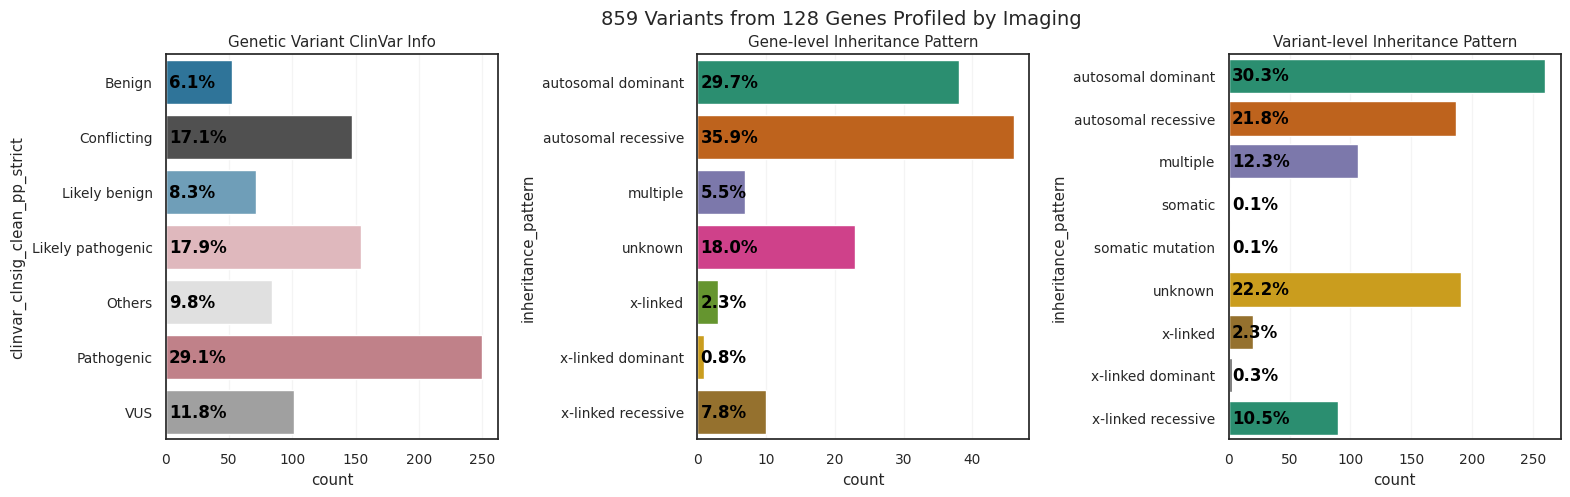

In [ ]:
fig, axes = plt.subplots(1,3,figsize=(18,5))
plot_cat_count_perc(
    imaging_summary_clinvar,
    "clinvar_clnsig_clean_pp_strict",
    title="ClinVar",
    ax=axes[0],
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
)
axes[0].set_title("Genetic Variant ClinVar Info")

plot_cat_count_perc(
    imaging_summary_clinvar.unique("symbol"),
    "inheritance_pattern",
    title="Inheritance",
    ax=axes[1],
)
axes[1].set_title("Gene-level Inheritance Pattern")

plot_cat_count_perc(
    imaging_summary_clinvar,
    "inheritance_pattern",
    title="Inheritance",
    ax=axes[2],
)
axes[2].set_title("Variant-level Inheritance Pattern")

plt.suptitle(f"{imaging_summary_clinvar.unique('gene_allele').shape[0]} Variants from {imaging_summary_clinvar.unique('symbol').shape[0]} Genes Profiled by Imaging", y=.97, fontsize=14)
plt.subplots_adjust(wspace=.6)
plt.show()

In [ ]:
summary_clin_var_counts

,clinvar_clnsig_clean_pp_strict,len
0,Others,71
1,VUS,52
2,Pathogenic,84
3,Benign,101
4,Likely pathogenic,147
5,Conflicting,154
6,Likely benign,250


In [33]:
# # Create pie chart for ClinVar annotation categories
# fig, ax = plt.subplots(1, 1, figsize=(8, 8))

# # Get the category counts from the merged data
# summary_clin_var_counts = imaging_summary_clinvar.group_by("clinvar_clnsig_clean_pp_strict").agg(pl.len()).to_pandas()
# category_order = clinvar_order_dict["original"]
# summary_clin_var_counts['clinvar_clnsig_clean_pp_strict'] = pd.Categorical(
#     imaging_summary_clinvar['clinvar_clnsig_clean_pp_strict'].unique(), 
#     categories=category_order, 
#     ordered=True
# )
# summary_clin_var_counts

# # Convert to pandas for easier plotting
# pie_data = summary_clin_var_counts.sort_values('clinvar_clnsig_clean_pp_strict')
# pie_data = pie_data.dropna()  # Remove any null values

# # Calculate percentages
# total_count = pie_data["len"].sum()
# pie_data["percentage"] = (pie_data["len"] / total_count * 100).round(1)

# # Create labels with counts and percentages
# labels = [f"{cat}\n({count}, {pct}%)" 
#           for cat, count, pct in zip(pie_data["clinvar_clnsig_clean_pp_strict"], 
#                                    pie_data["len"], 
#                                    pie_data["percentage"])]

# # Use a color palette that matches the boxenplot
# colors = list(palette_dict["clinvar_clnsig_clean_pp_strict"].values())
# # colors[1], colors[3] = colors[3], colors[1]  # Swap colors to match the order in pie chart
# # Create pie chart
# wedges, texts, autotexts = ax.pie(pie_data["len"], 
#                                   labels=labels, 
#                                   colors=colors,
#                                   autopct="",  # We're including percentages in labels
#                                   startangle=90,
#                                   textprops={'fontsize': 12})

# ax.set_title("Distribution of ClinVar Annotation Categories", fontsize=14, fontweight='bold', pad=20)

# # Equal aspect ratio ensures that pie is drawn as a circle
# ax.axis('equal')

# # # Add a legend
# # ax.legend(wedges, [f"{cat} (n={count})" for cat, count in zip(pie_data["clinvar_clnsig_clean"], pie_data["len"])],
# #           title="Categories",
# #           loc="center left",
# #           bbox_to_anchor=(1, 0, 0.5, 1))

# plt.tight_layout()
# plt.show()

# # Print summary statistics
# print("ClinVar Annotation Distribution:")
# print("=" * 40)
# for _, row in pie_data.iterrows():
#     print(f"{row['clinvar_clnsig_clean_pp_strict']}: {row['len']} variants ({row['percentage']}%)")
# print(f"\nTotal variants: {total_count}")

### 2.2 Gene-level Summary

In [34]:
# imaging_summary_clinvar.filter(
#     pl.col("clinvar_clnsig_clean_pp_strict")=="Benign"
# ).sort("AUROC_Mean_GFP", descending=True).select(
#     "gene_allele", "AUROC_Mean_GFP"
# ).head(15)

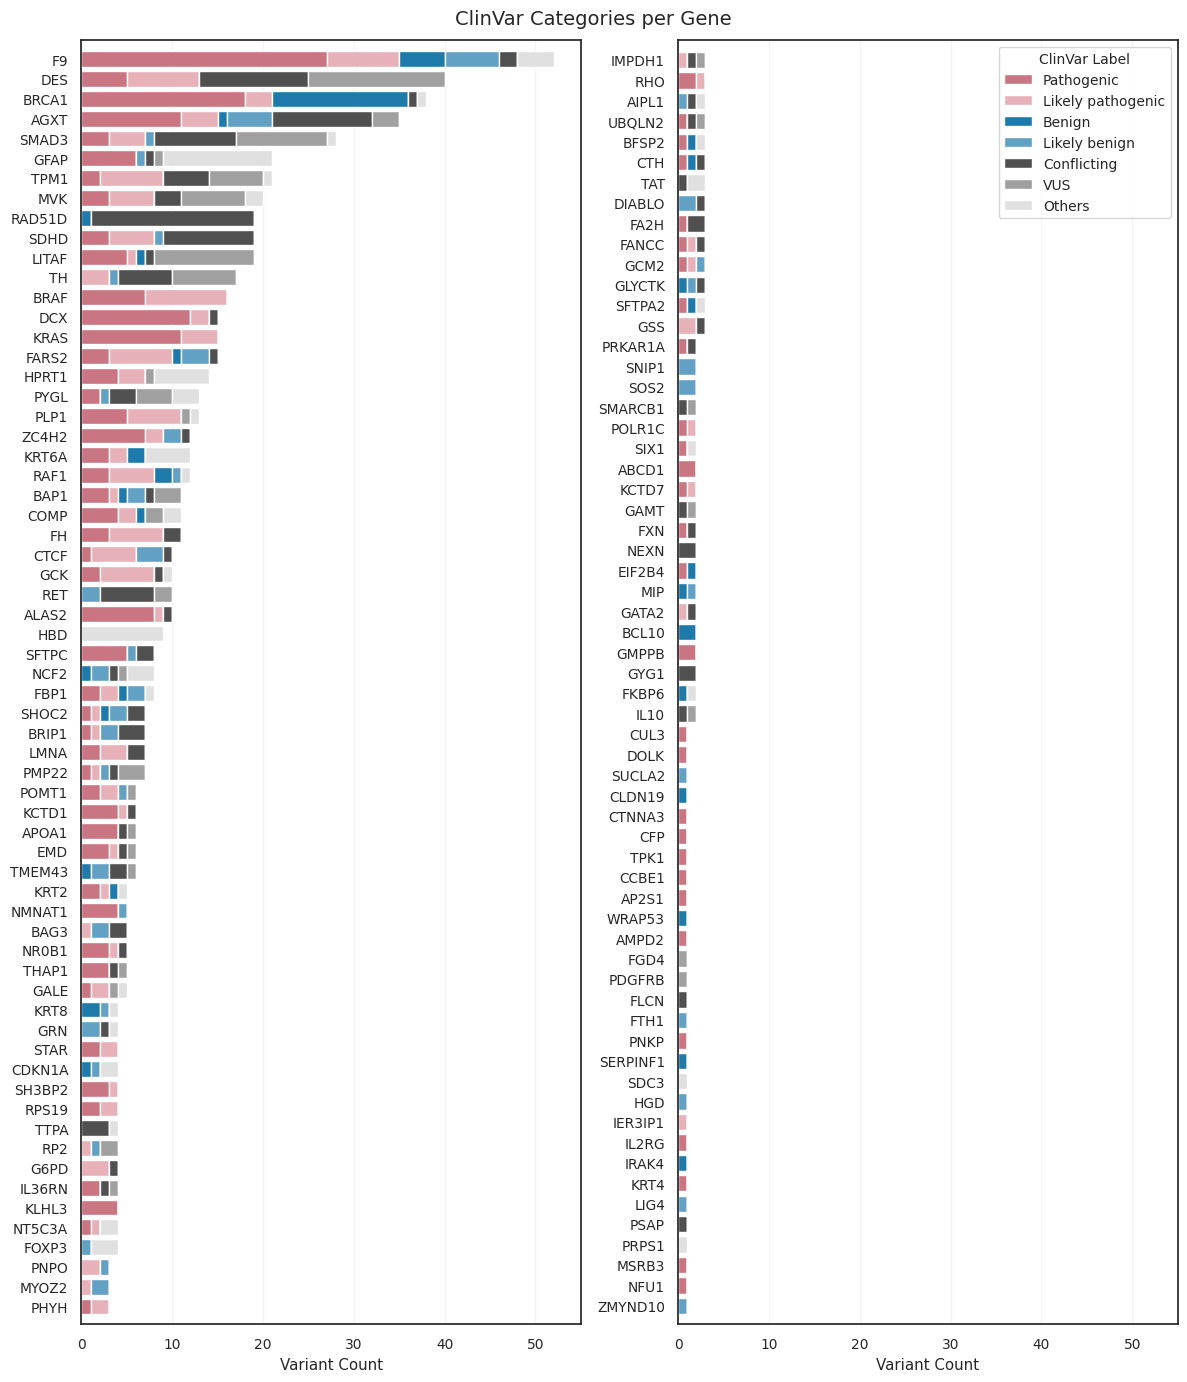

In [35]:
# 2. Count per (gene, category)
df = imaging_summary_clinvar.filter(
    pl.col("Metadata_Bio_Batch")!="2024_12_Batch_11-12"
).to_pandas() ## drop_nulls("clinvar_clnsig_clean").

top_num = int(np.ceil(imaging_summary_clinvar.unique("symbol").shape[0] / 2))
counts = (
    df.groupby(["symbol", "clinvar_clnsig_clean_pp_strict"])
    .size()
    .reset_index(name="count")
)
# 3. Pivot
pivot = counts.pivot(index="symbol", columns="clinvar_clnsig_clean_pp_strict", values="count").fillna(0)

# Add total count column and sort by it (descending)
pivot["total_count"] = pivot.sum(axis=1)
pivot_top = pivot.sort_values("total_count", ascending=False).head(top_num)
pivot_top = pivot_top.drop(columns=["total_count"])

# 4. Ensure category order
for cat in clinvar_order_dict["original"]:
    if cat not in pivot_top.columns:
        pivot_top[cat] = 0
pivot_top = pivot_top[clinvar_order_dict["original"]]

# 5. Plotting
fig, axes = plt.subplots(1,2, figsize=(12, 14))
# Get Set2 colors
bottom = None
for cat, color in palette_dict["clinvar_clnsig_clean_pp_strict"].items():
    axes[0].barh(pivot_top.index, pivot_top[cat], 
            left=bottom, label=cat, color=color)
    bottom = pivot_top[cat] if bottom is None else bottom + pivot_top[cat]
    
# Axis formatting
axes[0].set_xlabel("Variant Count")
axes[0].set_xlim(None, 55)
axes[0].set_ylim(-1, pivot_top.shape[0] - .1)  # Tighten y-axis to remove top/bottom gaps
# axes[0].set_title(f"ClinVar Categories per Gene (Top {top_num} with Most Variants)", fontsize=14)
axes[0].invert_yaxis()
axes[0].grid(alpha=.2, axis="x")

# ax.legend(title="ClinVar Label", fontsize=9, title_fontsize=10, loc="lower right")
# plt.tight_layout()
# plt.show()

pivot_bot = pivot.sort_values("total_count", ascending=False).iloc[top_num:,].copy()
pivot_bot = pivot_bot.drop(columns=["total_count"])

# 4. Ensure category order
for cat in clinvar_order_dict["original"]:
    if cat not in pivot_bot.columns:
        pivot_bot[cat] = 0
pivot_bot = pivot_bot[clinvar_order_dict["original"]]

bottom = None
for cat, color in palette_dict["clinvar_clnsig_clean_pp_strict"].items():
    axes[1].barh(pivot_bot.index, pivot_bot[cat], left=bottom, label=cat, color=color)
    bottom = pivot_bot[cat] if bottom is None else bottom + pivot_bot[cat]
    
# Axis formatting
axes[1].set_xlabel("Variant Count")
axes[1].set_xlim(None, 55)
axes[1].set_ylim(-1, pivot_bot.shape[0] - .1)  # Tighten y-axis to remove top/bottom gaps
# axes[1].set_title(f"ClinVar Categories per Gene ({top_num} After)", fontsize=14)
axes[1].invert_yaxis()
axes[1].legend(title="ClinVar Label", fontsize=10, title_fontsize=10, loc="upper right")
axes[1].grid(alpha=.2, axis="x")
plt.suptitle(f"ClinVar Categories per Gene", fontsize=14, y=.985)
plt.tight_layout()
plt.show()

<ipython-input-36-478565493fa6>:23: UserWarning: FixedFormatter should only be used together with FixedLocator
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')


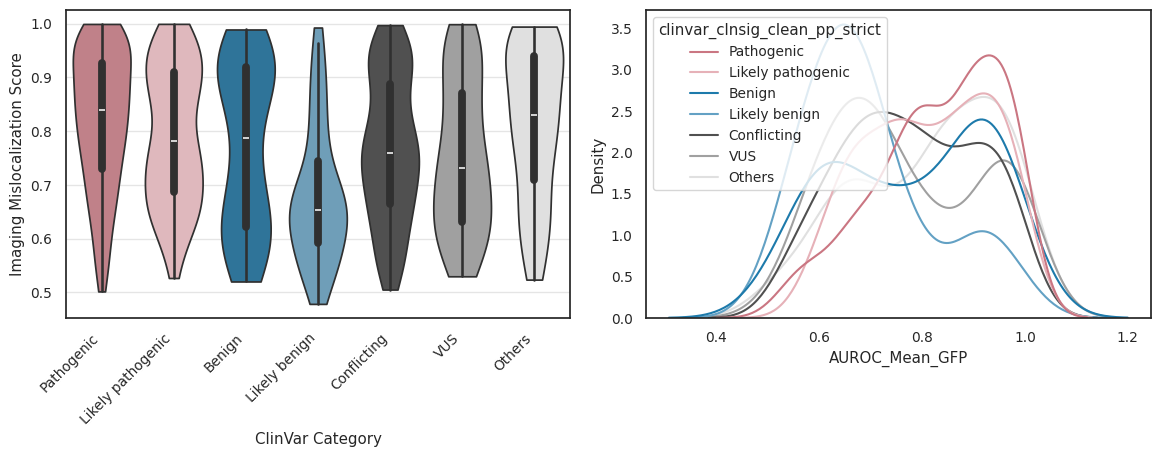

In [36]:
hue_order = clinvar_order_dict["original"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
# sns.boxenplot(
#     data=scores.to_pandas(),
#     x="clinvar_clnsig_clean", 
#     y="dualipa_abun_score",
#     hue="clinvar_clnsig_clean", 
#     palette=palette_dict["clinvar_clnsig_clean"],
#     order=hue_order,
#     ax=axes[0]
# )
sns.violinplot(
    data=df,
    x="clinvar_clnsig_clean_pp_strict", 
    y="AUROC_Mean_GFP_ADJ", ## AUROC_Mean_GFP
    hue="clinvar_clnsig_clean_pp_strict", 
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
    order=hue_order,
    cut=0,
    ax=axes[0]
)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
axes[0].set_xlabel("ClinVar Category") ##, rotation=45, ha='right'
axes[0].set_ylabel("Imaging Mislocalization Score") ##, rotation=45, ha='right'
axes[0].grid(alpha=0.5, axis="y")

sns.kdeplot(
    data=df,
    x="AUROC_Mean_GFP",
    hue="clinvar_clnsig_clean_pp_strict",
    hue_order=hue_order,
    ax=axes[1],
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
    common_norm=False
)
plt.subplots_adjust(wspace=0.15)
plt.show()

In [37]:
# plot_gene_level_summary(
#     imaging_summary_clinvar.with_columns(
#         (
#             (pl.col("Altered_95th_perc_both_batches_GFP"))
#         ).alias("hit_by_an_assay")
#     ).filter(
#         pl.col("Gene").is_in(imaging_summary_clinvar_hits["Gene"].unique())
#     ),
#     assay="hit_by_an_assay", 
#     cat="clinvar_clnsig_clean_pp_strict", 
#     palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
#     plot=True
# )

# plot_gene_level_summary(
#     imaging_summary_clinvar.with_columns(
#         (
#             (pl.col("Altered_95th_perc_both_batches_GFP"))
#         ).alias("hit_by_an_assay")
#     ).filter(
#         ~pl.col("Gene").is_in(imaging_summary_clinvar_hits["Gene"].unique())
#     ),
#     assay="hit_by_an_assay", 
#     cat="clinvar_clnsig_clean_pp_strict", 
#     palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
#     plot=True
# )

## 3. Analyses with different categories

### 3.1 ClinVar vs Inheritance

In [38]:
# fig, axes = plt.subplots(1,2,figsize=(14, 4.5))
# sns.kdeplot(
#     data=imaging_summary_clinvar.to_pandas(),
#     x="AUROC_Mean_GFP",
#     hue="clinvar_clnsig_clean",
#     palette=palette_dict["clinvar_clnsig_clean"],
#     common_norm=False,
#     hue_order=sorted(palette_dict["clinvar_clnsig_clean"].keys()),
#     ax=axes[0]
# )
# sns.boxenplot(
#     data=imaging_summary_clinvar.filter(
#         pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","3_Conflicting","4_VUS"])
#     ).to_pandas(),
#     y="AUROC_Mean_GFP",
#     x="clinvar_clnsig_clean",
#     hue="clinvar_clnsig_clean",
#     palette=palette_dict["clinvar_clnsig_clean"],
#     order=imaging_summary_clinvar.filter(
#         pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","3_Conflicting","4_VUS"])
#     ).group_by(
#         "clinvar_clnsig_clean"
#     ).agg(
#         pl.median("AUROC_Mean_GFP").alias("clinvar_median")
#     ).sort("clinvar_median", descending=True)["clinvar_clnsig_clean"],
#     # hue_order=sorted(palette_dict["clinvar_clnsig_clean"].keys()),
#     ax=axes[1]
# )
# axes[1].grid(alpha=.2, axis="y")
# # xtick_inher = axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=60, ha="right")

# fig, axes = plt.subplots(1,2,figsize=(14, 4.5))
# sns.kdeplot(
#     data=imaging_summary_clinvar.to_pandas(),
#     x="AUROC_Mean_GFP",
#     hue="inheritance_pattern",
#     palette="Set2",
#     common_norm=False,
#     ax=axes[0],
#     warn_singular=False
# )
# axes[1].grid(alpha=.2)
# sns.boxenplot(
#     data=imaging_summary_clinvar.to_pandas(),
#     y="AUROC_Mean_GFP",
#     x="inheritance_pattern",
#     # hue="inheritance_pattern",
#     # palette="Dark2",
#     order=imaging_summary_clinvar.group_by(
#         "inheritance_pattern"
#     ).agg(
#         pl.median("AUROC_Mean_GFP").alias("inher_median")
#     ).sort("inher_median", descending=True)["inheritance_pattern"],
#     # hue_order=sorted(clinvar_palette_old.keys()),
#     ax=axes[1],
# )

# xtick_inher = axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=60, ha="right")
# axes[1].grid(alpha=.2, axis="y")
# plt.subplots_adjust(wspace=.15)
# plt.show()

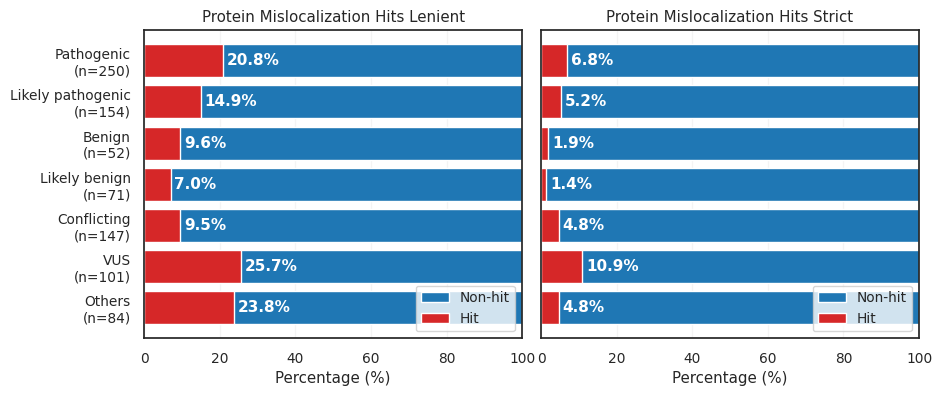

In [41]:
img_metric_df = imaging_summary_clinvar.with_columns(
    (pl.col(GFP_MISLOCAL_FEAT_STRICT)==1).alias("img_prot_hits_5perc_strict"),
    (pl.col(GFP_MISLOCAL_FEAT_LENIENT)==1).alias("img_prot_hits_5perc"),
    pl.col("gene_allele").alias("gene_variant"),
    pl.col("clinvar_clnsig_clean_pp_strict")
        .cast(pl.Enum(clinvar_order_dict["original"]))
).sort("clinvar_clnsig_clean_pp_strict")

fig, axes = plt.subplots(1,2,figsize=(10,4),sharey=True)
# plot_assay_hit_by_category_perc
plot_assay_hit_by_category_perc(img_metric_df, "img_prot_hits_5perc", "clinvar_clnsig_clean_pp_strict", f"Protein Mislocalization Hits Lenient", ax=axes[0])
plot_assay_hit_by_category_perc(img_metric_df, "img_prot_hits_5perc_strict", "clinvar_clnsig_clean_pp_strict", f"Protein Mislocalization Hits Strict", ax=axes[1])
plt.subplots_adjust(wspace=.05)
plt.show()

<ipython-input-80-40b7296c1372>:16: UserWarning: FixedFormatter should only be used together with FixedLocator
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')


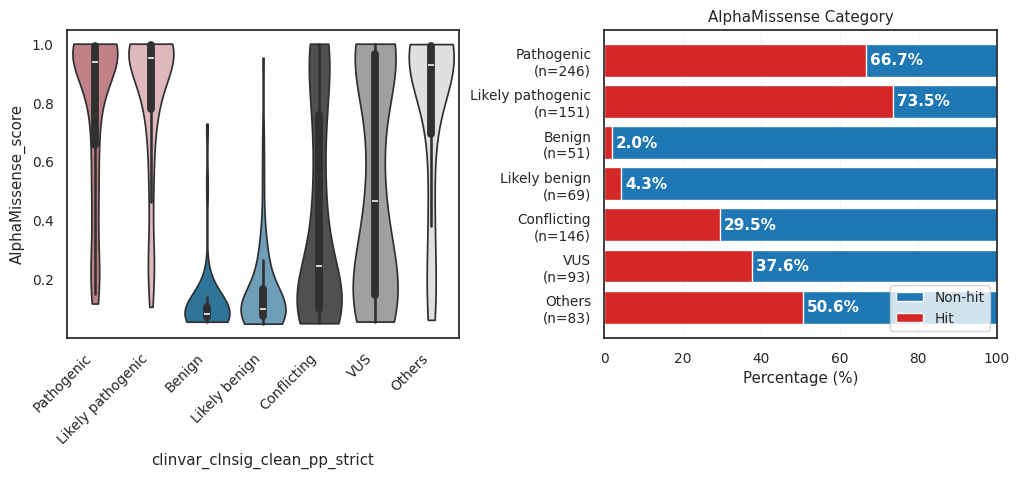

In [80]:
df["AlphaMissense_score"] = df["AlphaMissense_score"].replace(".",np.nan).astype(float)
df["AlphaMissense_pred_call"] = df["AlphaMissense_pred"].astype(str).apply(lambda x : True if "P" in x else False)
df["gene_variant"] = df["gene_allele"]

fig, axes = plt.subplots(1,2,figsize=(12,4),sharey=False)
sns.violinplot(
    data=df,
    x="clinvar_clnsig_clean_pp_strict", 
    y="AlphaMissense_score", ## AUROC_Mean_GFP
    hue="clinvar_clnsig_clean_pp_strict", 
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
    order=hue_order,
    cut=0,
    ax=axes[0]
)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')

plot_assay_hit_by_category_perc(
    pl.DataFrame(df).with_columns(
        pl.col("clinvar_clnsig_clean_pp_strict")
            .cast(pl.Enum(clinvar_order_dict["original"]))
    ).sort("clinvar_clnsig_clean_pp_strict"), 
    "AlphaMissense_pred_call", 
    "clinvar_clnsig_clean_pp_strict", 
    f"AlphaMissense Category", 
    ax=axes[1]
)
plt.subplots_adjust(wspace=0.37)
plt.show()

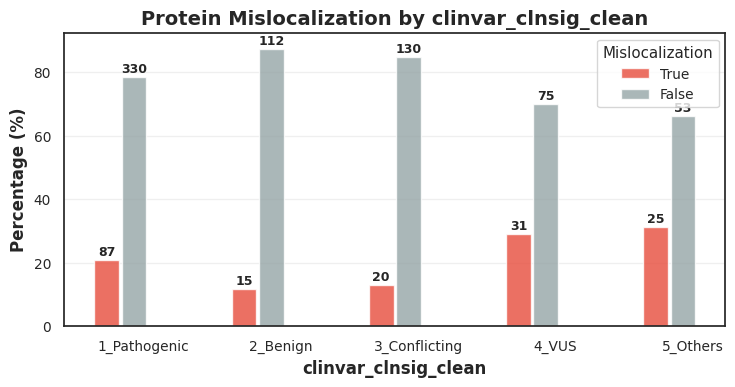

clinvar_clnsig_clean,img_prot_hits_5perc,len,total_count,percentage
str,bool,u32,u32,f64
"""1_Pathogenic""",null,3,420,0.7
"""1_Pathogenic""",false,330,420,78.6
"""1_Pathogenic""",true,87,420,20.7
"""2_Benign""",null,1,128,0.8
"""2_Benign""",false,112,128,87.5
…,…,…,…,…
"""4_VUS""",false,75,107,70.1
"""4_VUS""",true,31,107,29.0
"""5_Others""",null,2,80,2.5


In [17]:
def plot_dualipa_by_cat(df_processed, category, clinvar_categories=None, ax=None):
   # Count occurrences
   summary_df = df_processed.group_by([category, "img_prot_hits_5perc"]).len().sort([category, "img_prot_hits_5perc"])
   # Get total counts per clinvar category for percentage calculation
   total_counts = df_processed.group_by(category).len().rename({"len": "total_count"})
   
   # Join and calculate percentages
   summary_with_pct = summary_df.join(total_counts, on=category).with_columns([
       (pl.col("len") / pl.col("total_count") * 100).round(1).alias("percentage")
   ])
   # Convert to pandas for plotting
   plot_df = summary_with_pct.to_pandas()
   # Color palette for abundance categories
   abundance_colors = {
       True: '#e74c3c',      # Red
    #    False: '#3498db',      # Blue  
       False: '#95a5a6',  # Gray
    #    'Uncertain': '#f39c12'      # Orange
   }
   if clinvar_categories is None:
       clinvar_categories = plot_df[category].unique()
       
   # Create the plot
   if ax is None:
       fig, ax = plt.subplots(figsize=(len(clinvar_categories)*1.5, 4))
   
   x_pos = range(len(clinvar_categories))
   
   # Plot bars for each abundance category
   bar_width = 0.18
   bar_gap = 0.02  # Gap between bars within the same category
   abundance_cats = [True, False]

   max_height = 0
   for i, cat in enumerate(abundance_cats):
       cat_data = plot_df[plot_df['img_prot_hits_5perc'] == cat]
       
       # Align data with clinvar categories (fill missing with 0)
       counts = []
       percentages = []
       for clinvar_cat in clinvar_categories:
           row = cat_data[cat_data[category] == clinvar_cat]
           if len(row) > 0:
               counts.append(row['len'].iloc[0])
               percentages.append(row['percentage'].iloc[0])
           else:
               counts.append(0)
               percentages.append(0.0)
       
       # Plot bars with percentages as height
       bars = ax.bar([x + i * (bar_width + bar_gap) for x in x_pos], percentages, 
                     bar_width, label=cat, color=abundance_colors[cat], alpha=0.8)

       # Add count labels on bars
       for j, (bar, count, pct) in enumerate(zip(bars, counts, percentages)):
           if pct > 0:
               height = bar.get_height()
               max_height = max(max_height, height)
               ax.text(bar.get_x() + bar.get_width()/2., height + 0.5,
                      f'{count}', ha='center', va='bottom', fontsize=9, fontweight='bold')
   
   # Customize the plot
   ax.set_xlabel(category, fontsize=12, fontweight='bold')
   ax.set_ylabel('Percentage (%)', fontsize=12, fontweight='bold')
   ax.set_title(f'Protein Mislocalization by {category}', fontsize=14, fontweight='bold')
   ax.set_xticks([x + bar_width * 1.5 for x in x_pos])
   ax.set_xticklabels(clinvar_categories, rotation=0, ha='center')
   ax.legend(title='Mislocalization', loc='best')
   ax.grid(axis='y', alpha=0.3)
   ax.set_ylim(0, max_height+5)
   
   plt.tight_layout()
   plt.show()
   
   # Print summary statistics
   # print("Summary Statistics:")
   # with pl.Config(set_tbl_rows=25):
   #     display(summary_with_pct)

   return summary_with_pct

plot_dualipa_by_cat(img_metric_df, "clinvar_clnsig_clean")

#### 3.1.1 AUROC's predictive power for pathogenicity

In [ ]:
ap_results_dict = plot_auroc_curves(imaging_summary_clinvar, "1_Pathogenic", 
                                    methods=["AUROC_Mean_GFP"])
sys.path.insert(1, "../../../../4_compare_ai_scores/2_analysis/scripts")
from yogiroc import *

def plot_adjusted_pr_curves(df_clinvar_w_scores, pos_label, methods, monotonized_flag=True, balanced_flag=True, subsample=False, n_bootstrap=1000, random_state=None):
    """
    For each method, plot the adjusted PR curve (with both balanced and monotonized adjustments)
    and compute the adjusted AUPRC via bootstrapping. Also perform pairwise significance testing 
    of the AUPRC across different RSA categories.
    
    Parameters
    ----------
    df_clinvar_w_scores : Polars DataFrame
        Input data including columns "clinvar_clnsig_clean", category and predictor scores.
    methods : list of str
        List of method names corresponding to score columns in the data.
    set2_palette : list of str
        List of colors (e.g., from a color palette) to use for different RSA categories.
    n_bootstrap : int, optional
        Number of bootstrap iterations for significance testing (default is 1000).
    random_state : int or None, optional
        Seed for reproducibility.
    
    Returns
    -------
    ap_results : dict
        Dictionary of adjusted AUPRC values and bootstrap distributions, structured as:
          { method: { category: {"AP": <adjusted AUPRC>, "boot_ap": <bootstrap array> } } }
    significance : dict
        Dictionary mapping each method to a DataFrame of pairwise p-values comparing AUPRC between categories.
    """
    assert (balanced_flag and not subsample) or (subsample and not balanced_flag) or (not subsample and not balanced_flag)
    
    ap_results_dict = {}
    # sig_results_dict = {}
    fig, axes = plt.subplots(1, len(methods), figsize=(4 * len(methods), 4))
    if len(methods) == 1:
        axes = [axes]
        
    ap_results = {}  # to store adjusted AUPRC and bootstrap distributions
    for m_idx, met in enumerate(methods):
        ap_results[met] = {}
        # Filter data for current category and valid clinical labels.
        df_clin_per_method = df_clinvar_w_scores.filter(
            (pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"]))
        ).with_columns(
            (
                pl.when(pl.col("clinvar_clnsig_clean") == pos_label)
                .then(1)
                .otherwise(0)
            ).alias("clinvar_label")
        ).drop_nulls(subset=["clinvar_clnsig_clean", met])

        if pos_label == "2_Benign":
            df_clin_per_method = df_clin_per_method.with_columns(
                (
                    pl.col(met).neg()
                ).alias(met)
            )
        
        # Convert to pandas DataFrame.
        df_pd = df_clin_per_method.to_pandas()
        if subsample:
            # Assume df is your existing DataFrame with a column named "label"
            # Find the minimum count among the two classes (0 and 1)
            min_count = df_pd['clinvar_label'].value_counts().min()
            # Group by the 'label' column and sample min_count rows from each group (without replacement)
            df_pd = df_pd.groupby('clinvar_label').apply(lambda x: x.sample(n=min_count, random_state=42)).reset_index(drop=True)

        # Convert clinvar_label to boolean.
        truth = df_pd["clinvar_label"].astype(bool)
        # Create a scores DataFrame (with one column).
        scores = df_pd[[met]]

        # Create the YogiROC2 object using the new YogiROC2() constructor.
        yrobj = YogiROC2(truth, scores, names=[met], high=True)
        # Get the performance table from the YogiROC2 object.
        table = yrobj.tables[met]

        if (monotonized_flag and balanced_flag):
            table = table.dropna()
        precision = configure_prec(table, monotonized_flag=monotonized_flag, balanced_flag=balanced_flag)
        recall = table["tpr_sens"].values
        # print(precision)
        # print(recall)
        ap = calc_auc(recall[~np.isnan(recall)], precision[~np.isnan(precision)])
        ap_results[met] = {"AUPRC": ap}

        # Plot the adjusted PR curve.
        axes[m_idx].plot(100 * recall, 100 * precision,
                        label=f"{met}: {ap:.2f}")
        # Plot chance level as a horizontal dashed line.
        prior = np.sum(truth) / df_pd.shape[0]
        if (not balanced_flag):
            axes[m_idx].axhline(y=100 * prior, color=set2_palette[plddt_cats.index(cat)], ls="--")
    
        # Customize the subplot.
        handles, labels = axes[methods.index(met)].get_legend_handles_labels()
        precision_label = "Precision (%)"
        title = f"AUPRC\nby {met}"
        
        if balanced_flag:
            precision_label = "Balanced " + precision_label
            title = "Balanced " + title
        if monotonized_flag:
            precision_label = "Monotonized " + precision_label
    
        axes[m_idx].legend(
                        loc="lower left",
                        title=title)
        axes[m_idx].set_xlabel("Recall (%)")
        axes[m_idx].set_ylabel(precision_label)
        axes[m_idx].set_title("Adjusted AUPRC")
        axes[m_idx].grid()

    # sig_results_dict[category] = significance

    plt.tight_layout()
    plt.show()
    # plt.subplots_adjust(wspace=0.04)
    
    return None ## , sig_results_dict

plot_adjusted_pr_curves(imaging_summary_clinvar, "1_Pathogenic", 
                        methods=["AUROC_Mean_GFP"])

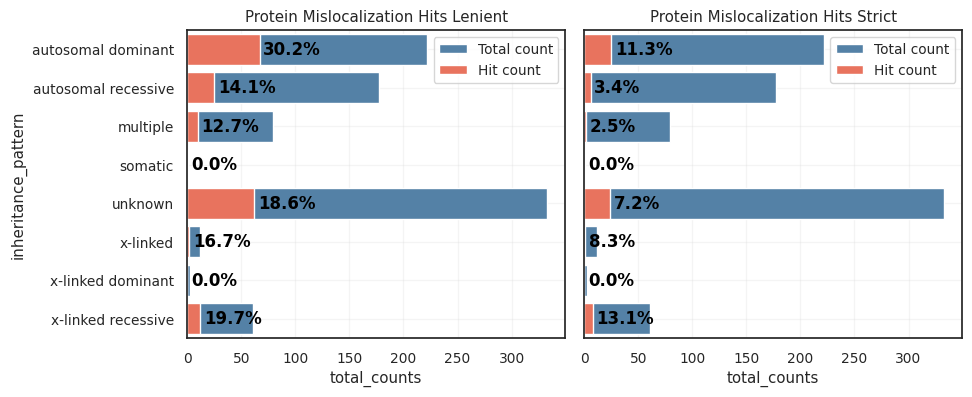

In [20]:
fig, axes = plt.subplots(1,2,figsize=(10,4), sharey=True)
plot_assay_hit_by_category(img_metric_df.drop_nulls("inheritance_pattern"), "img_prot_hits_5perc", "inheritance_pattern", f"Protein Mislocalization Hits Lenient", ax=axes[0])
plot_assay_hit_by_category(img_metric_df.drop_nulls("inheritance_pattern"), "img_prot_hits_5perc_strict", "inheritance_pattern", f"Protein Mislocalization Hits Strict", ax=axes[1])
plt.subplots_adjust(wspace=.05)
plt.show()

## 4. Protein Structural Analyses

### 4.1 pLDDT and RSA

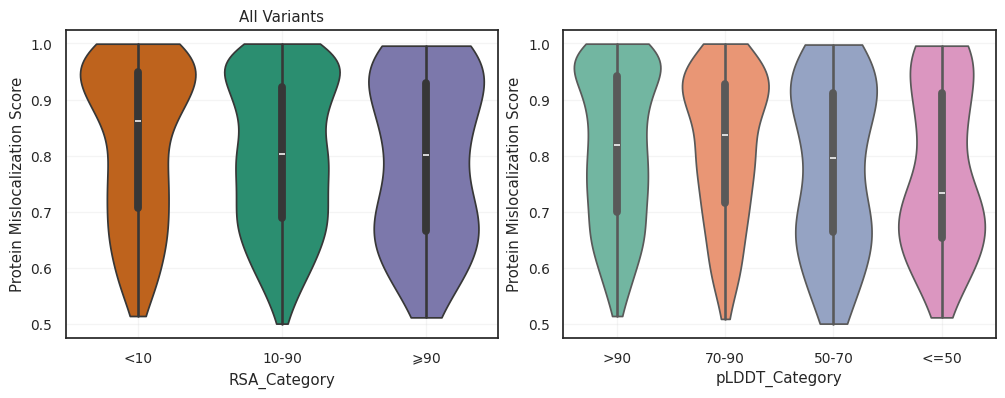

In [35]:
# fig, axes = plt.subplots(1,2,figsize=(10,4))
# plot_assay_hit_by_category(img_metric_df.drop_nulls("RSA_Category"), "img_prot_hits_5perc", "RSA_Category", f"Protein Mislocalization Hits Lenient RSA", ax=axes[0])
# plot_assay_hit_by_category(img_metric_df.drop_nulls("pLDDT_Category"), "img_prot_hits_5perc", "pLDDT_Category", f"Protein Mislocalization Hits Lenient pLDDT", ax=axes[1])
# plt.subplots_adjust(wspace=.25)
# plt.show()

fig, axes = plt.subplots(1,2,figsize=(12, 4))
# sns.kdeplot(
#     data=imaging_summary_clinvar.to_pandas(),
#     x="AUROC_Mean_GFP",
#     hue="RSA_Category",
#     palette="Set2",
#     common_norm=False,
#     # hue_order=sorted(clinvar_palette_old.keys()),
#     ax=axes[0]
# )
# sns.kdeplot(
#     data=imaging_summary_clinvar.to_pandas(),
#     x="AUROC_Mean_GFP",
#     hue="pLDDT_Category",
#     palette="Set2",
#     common_norm=False,
#     # hue_order=sorted(clinvar_palette_old.keys()),
#     ax=axes[1]
# )
plot_data = imaging_summary_clinvar.drop_nulls("RSA_Category").to_pandas()
sns.violinplot(
    data=plot_data,
    y="AUROC_Mean_GFP",
    x="RSA_Category",
    hue="RSA_Category",
    palette="Dark2",
    # common_norm=False,
    order=imaging_summary_clinvar.drop_nulls("RSA_Category").group_by(
        "RSA_Category"
    ).agg(
        pl.median("AUROC_Mean_GFP").alias("inher_median")
    ).sort("inher_median", descending=True)["RSA_Category"],
    ax=axes[0],
    cut=0
)
groups_order = imaging_summary_clinvar.drop_nulls("RSA_Category").group_by(
    "RSA_Category"
).agg(
    pl.median("AUROC_Mean_GFP").alias("inher_median")
).sort("inher_median", descending=True)["RSA_Category"]
# Add mean markers as triangles
# for j, group in enumerate(groups_order):
#     group_data = plot_data[plot_data["RSA_Category"] == group]
#     if not group_data.empty:
#         group_mean = group_data["AUROC_Mean_GFP"].mean()
#         axes[0].scatter(j, group_mean, marker="^", s=120, 
#                         color="tomato", #edgecolors="black", 
#                         linewidth=1.5, zorder=10)
axes[0].set_title("All Variants")
plot_data = imaging_summary_clinvar.drop_nulls("pLDDT_Category").to_pandas()
groups_order = ['>90', '70-90', '50-70', '<=50']

sns.violinplot(
    data=plot_data,
    y="AUROC_Mean_GFP",
    x="pLDDT_Category",
    hue="pLDDT_Category",
    palette="Set2",
    order=groups_order,
    cut=0,
    # common_norm=False,
    # hue_order=sorted(clinvar_palette_old.keys()),
    ax=axes[1]
)
# Add mean markers as triangles
# for j, group in enumerate(groups_order):
#     group_data = plot_data[plot_data["pLDDT_Category"] == group]
#     if not group_data.empty:
#         group_mean = group_data["AUROC_Mean_GFP"].mean()
#         axes[1].scatter(j, group_mean, marker="^", s=120, 
#                         color="tomato", #edgecolors="black", 
#                         linewidth=1.5, zorder=10)

axes[0].set_ylabel("Protein Mislocalization Score")
axes[1].set_ylabel("Protein Mislocalization Score")

axes[0].grid(alpha=.2)
axes[1].grid(alpha=.2)
plt.subplots_adjust(wspace=.15)
plt.show()

In [22]:
imaging_summary_clinvar.drop_nulls("pLDDT_Category").group_by(
        "pLDDT_Category"
    ).agg(
        pl.median("AUROC_Mean_GFP").alias("inher_median")
    ).sort("inher_median", descending=True)["pLDDT_Category"].to_list()

['70-90', '>90', '50-70', '<=50']

In [28]:
with pl.Config(set_tbl_rows=20):
    display(
        imaging_summary_clinvar.group_by(
        "RSA_Category","symbol"
    ).agg(pl.len()).sort(
        ["symbol","len"],
        descending=[False, True]
    ).filter(
        pl.col("len")>10
    )
)

RSA_Category,symbol,len
str,str,u32
"""10-90""","""AGXT""",17
"""<10""","""AGXT""",17
"""10-90""","""BRCA1""",22
"""10-90""","""DES""",37
"""10-90""","""F9""",28
"""<10""","""F9""",19
"""10-90""","""GFAP""",24
"""10-90""","""KRAS""",12
"""10-90""","""KRT6A""",11


<ipython-input-39-a83675a1a782>:5: UserWarning: The palette list has more values (8) than needed (3), which may not be intended.
  ax = sns.violinplot(


<Figure size 640x480 with 0 Axes>

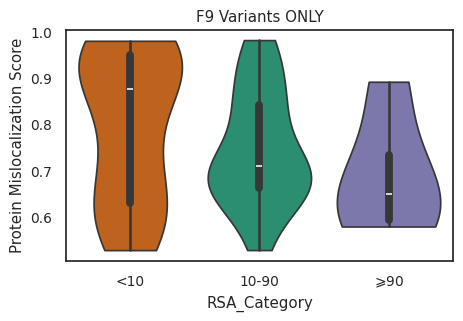

In [39]:
plt.clf()
palette = sns.color_palette("Dark2")
# palette[0], palette[1] = palette[1], palette[0]
fig, ax = plt.subplots(1,1,figsize=(5,3))
ax = sns.violinplot(
    data=imaging_summary_clinvar.filter(
        pl.col("symbol")=="F9"
    ).unique("gene_allele").to_pandas(),#,[df_with_metrics["protein_Domain (UniProt)"]=="Peptidase S1"],
    y="AUROC_Mean_GFP",
    x="RSA_Category",
    palette=palette,
    hue="RSA_Category",
    order=imaging_summary_clinvar.drop_nulls("RSA_Category").group_by(
        "RSA_Category"
    ).agg(
        pl.median("AUROC_Mean_GFP").alias("inher_median")
    ).sort("inher_median", descending=True)["RSA_Category"],
    ax=ax,
    cut=0
)
ax.set_ylabel("Protein Mislocalization Score")
ax.set_title("F9 Variants ONLY")
plt.show()

### 4.2 Other Structural Features (G2P)

Feature Categories for Subcellular Localization Analysis:

Signal Sequences Targeting:
  - protein_Signal (UniProt)
  - protein_Transit peptide (UniProt)
  - protein_Transmembrane (UniProt)
  - protein_Topological domain (UniProt)
  - protein_Intramembrane (UniProt)

Nuclear Targeting:
  - protein_Motif (UniProt)
  - protein_Region (UniProt)

Structural Context:
  - protein_Hydropathy
  - protein_Secondary structure (DSSP 3-state)*
  - protein_Secondary structure (DSSP 9-state)*
  - protein_Accessible surface area (Å²)*
  - protein_AlphaFold confidence (pLDDT)

Post Translational Modifications:
  - protein_Lipidation (UniProt)
  - protein_Glycosylation (UniProt)
  - protein_Modified residue (UniProt)
  - protein_Acetylation
  - protein_Phosphorylation
  - protein_Ubiquitination

Protein Domains Sites:
  - protein_Domain (UniProt)
  - protein_Active site (UniProt)
  - protein_Binding site (UniProt)
  - protein_Coiled coil (UniProt)
  - protein_Zinc finger (UniProt)

Dataset shape: (888,

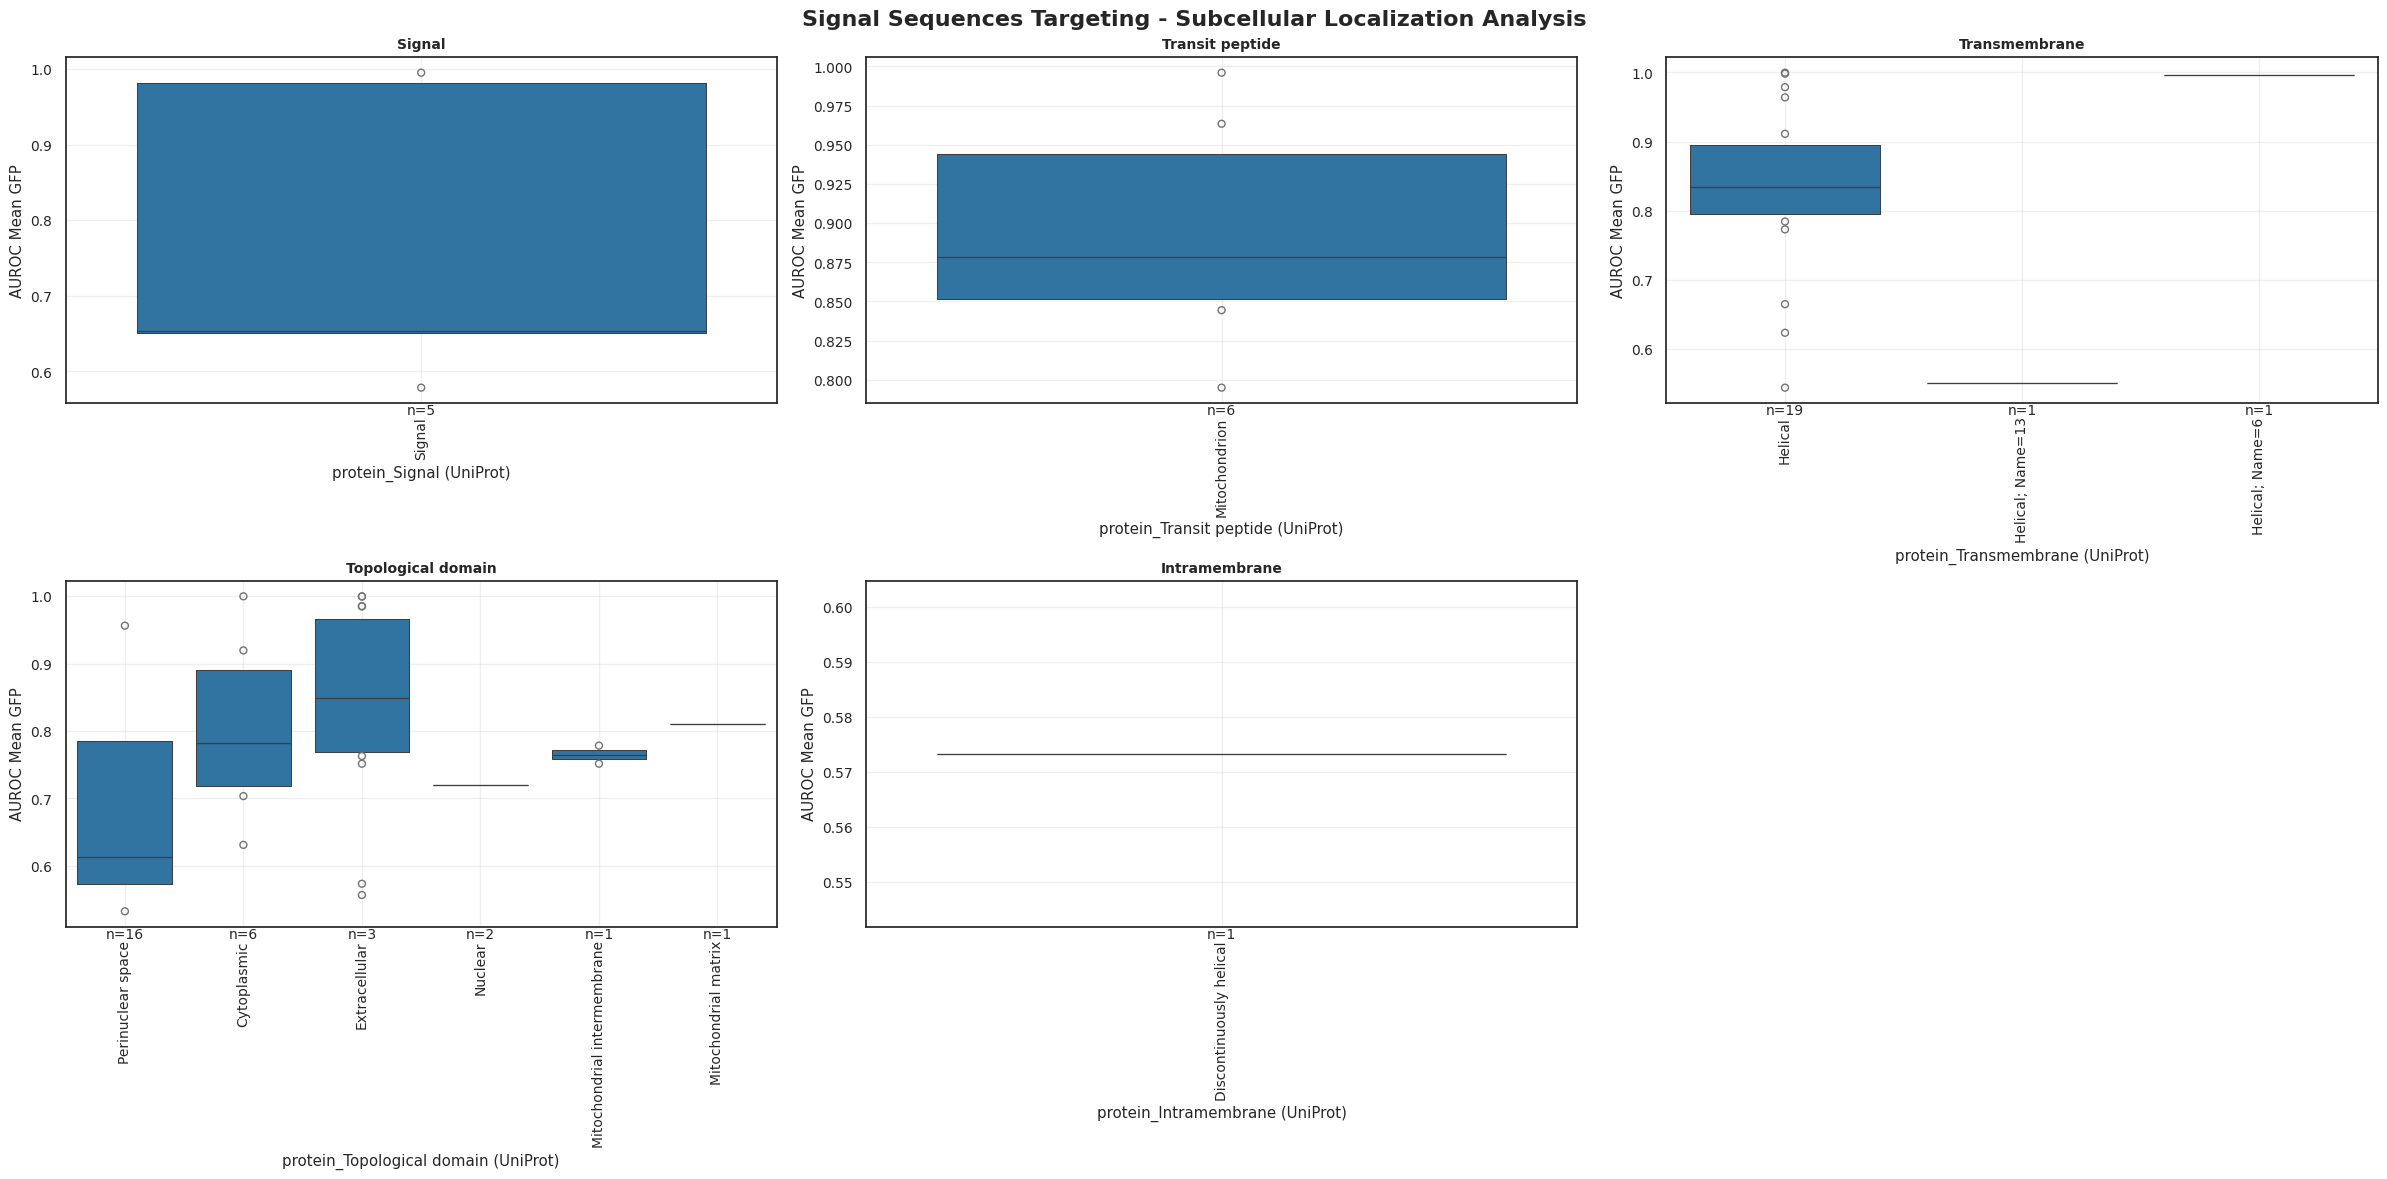


Signal Sequences Targeting Summary:
Features analyzed: 5
  protein_Signal (UniProt): categorical, 5 non-null values
  protein_Transit peptide (UniProt): categorical, 6 non-null values
  protein_Transmembrane (UniProt): categorical, 21 non-null values
  protein_Topological domain (UniProt): categorical, 29 non-null values
  protein_Intramembrane (UniProt): categorical, 1 non-null values

ANALYZING: Nuclear Targeting


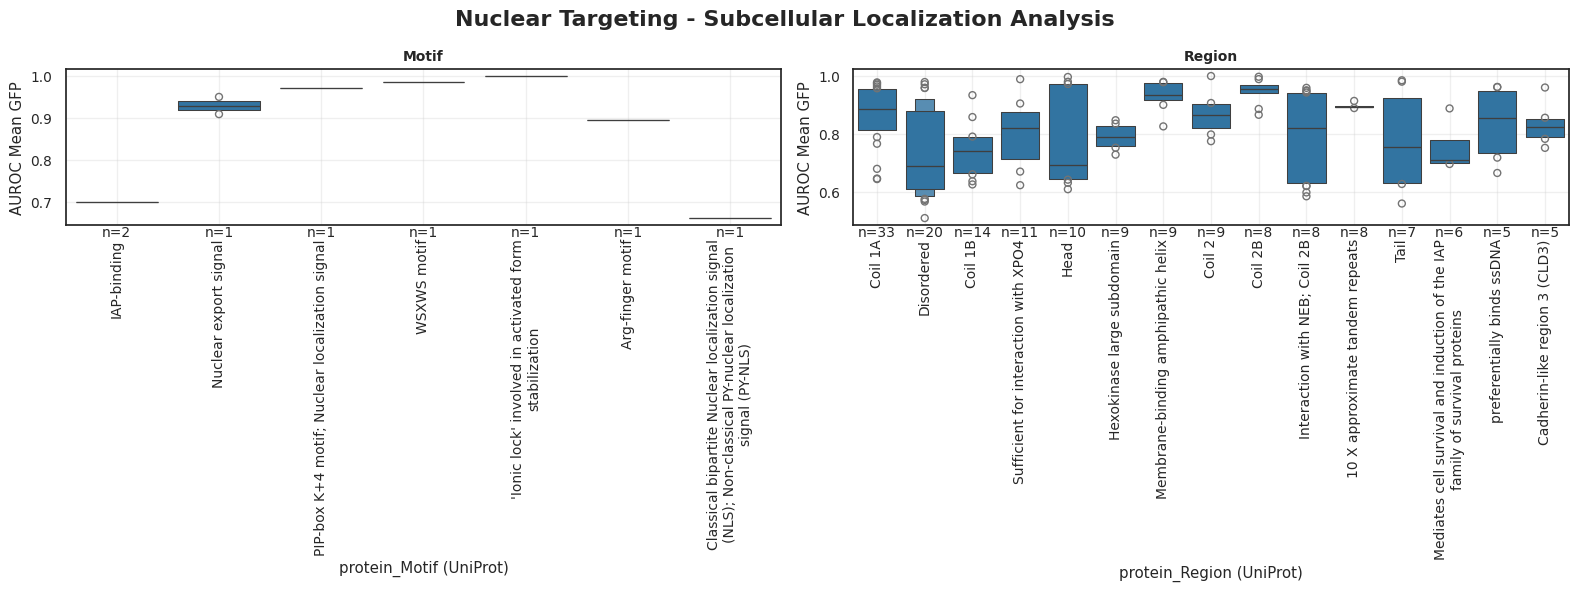


Nuclear Targeting Summary:
Features analyzed: 2
  protein_Motif (UniProt): categorical, 8 non-null values
  protein_Region (UniProt): categorical, 207 non-null values

ANALYZING: Structural Context


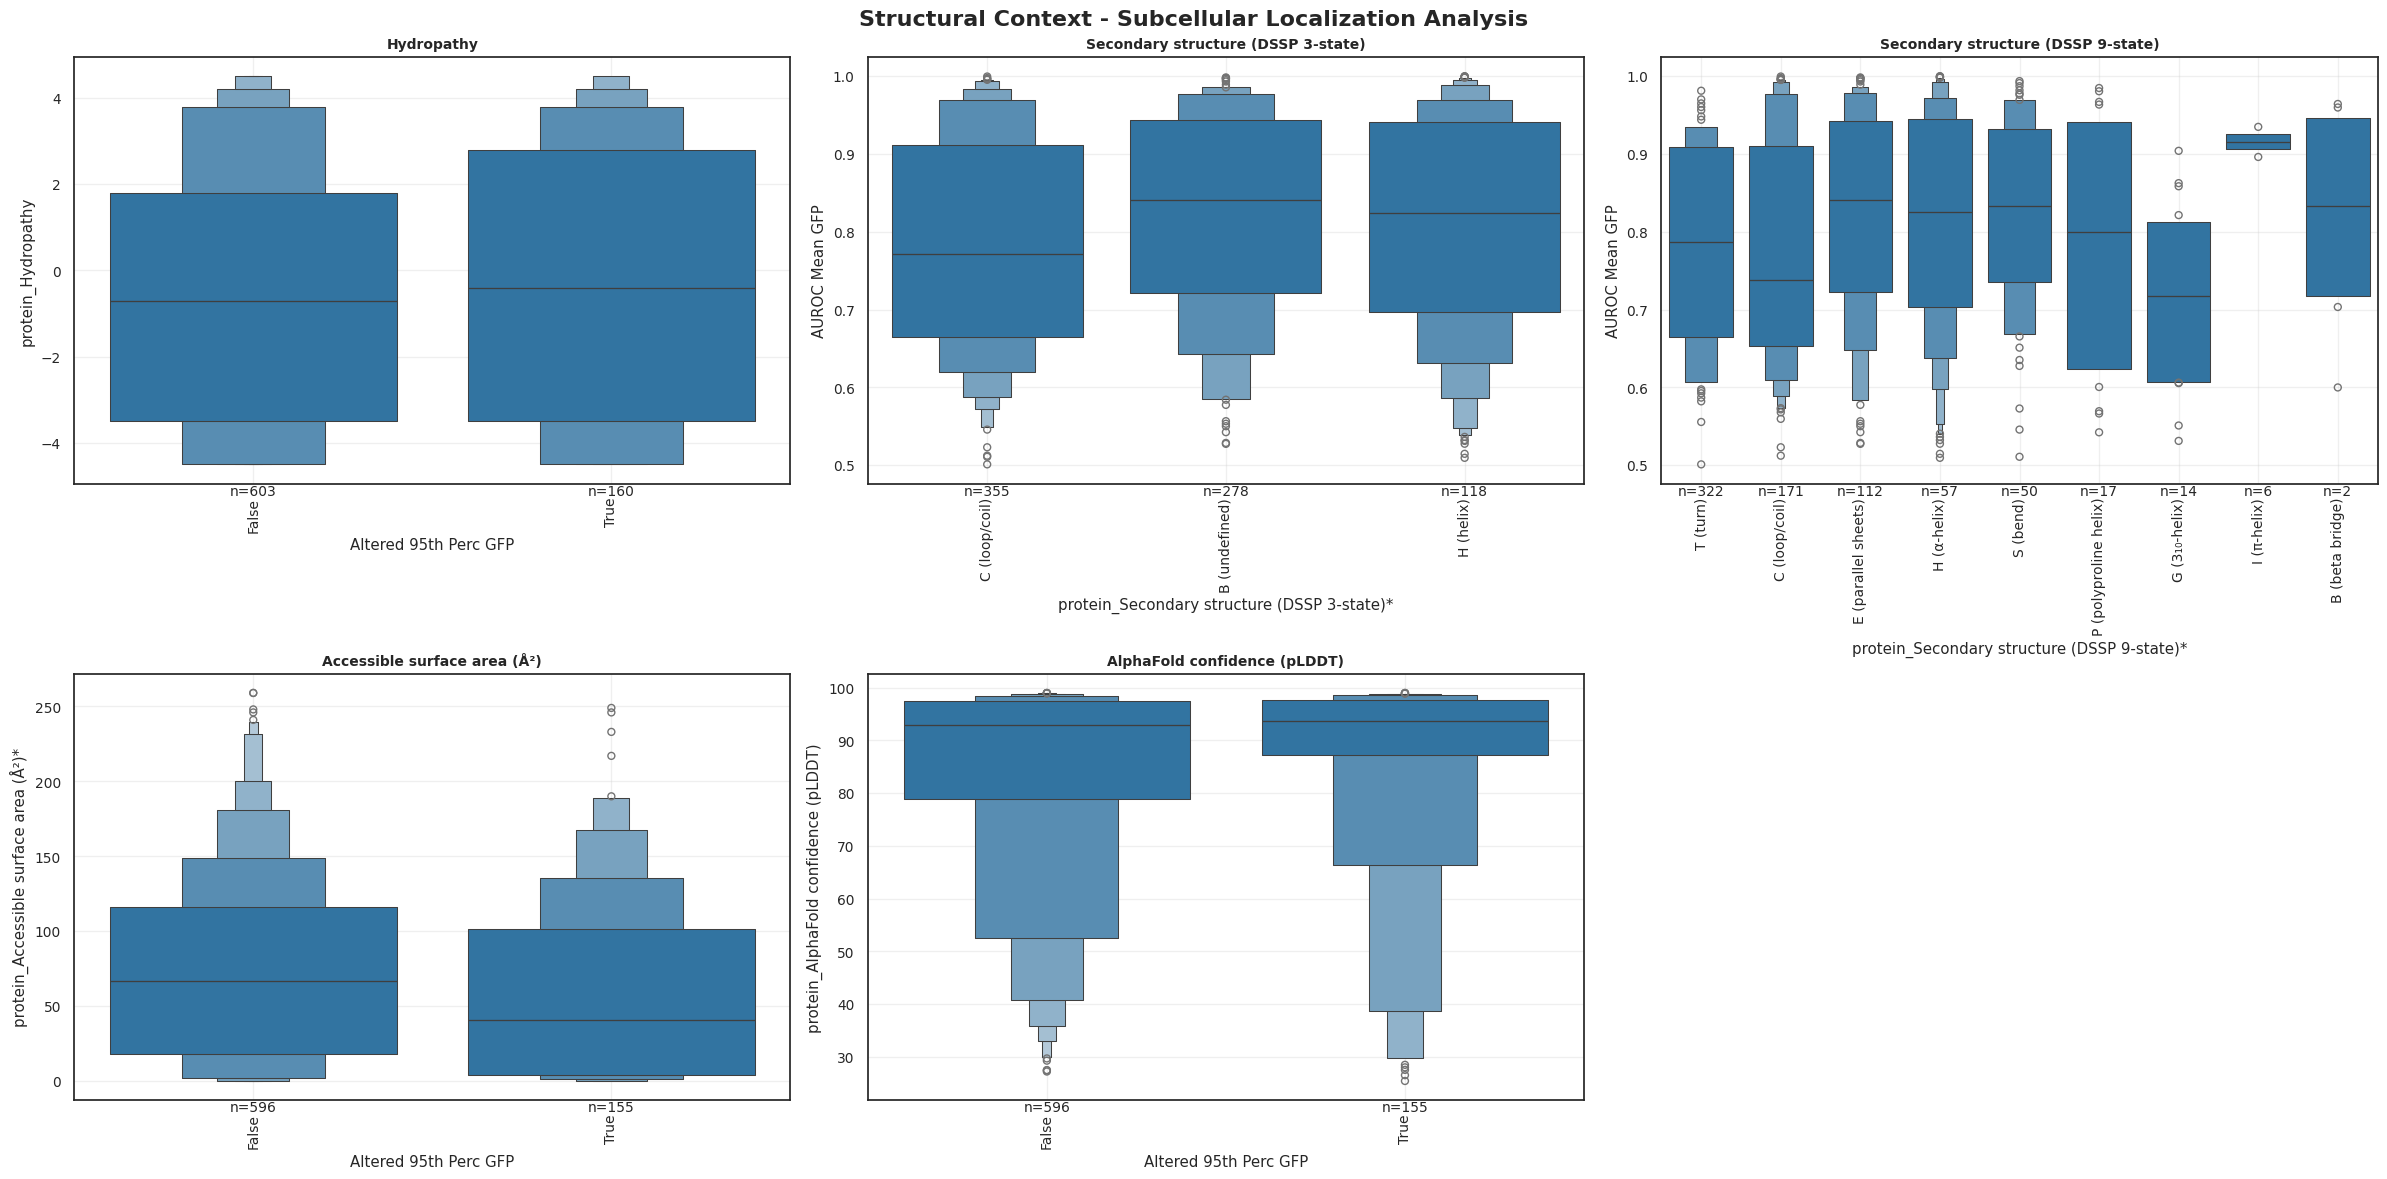


Structural Context Summary:
Features analyzed: 5
  protein_Hydropathy: continuous, 768 non-null values
  protein_Secondary structure (DSSP 3-state)*: categorical, 756 non-null values
  protein_Secondary structure (DSSP 9-state)*: categorical, 756 non-null values
  protein_Accessible surface area (Å²)*: continuous, 756 non-null values
  protein_AlphaFold confidence (pLDDT): continuous, 756 non-null values

ANALYZING: Post Translational Modifications


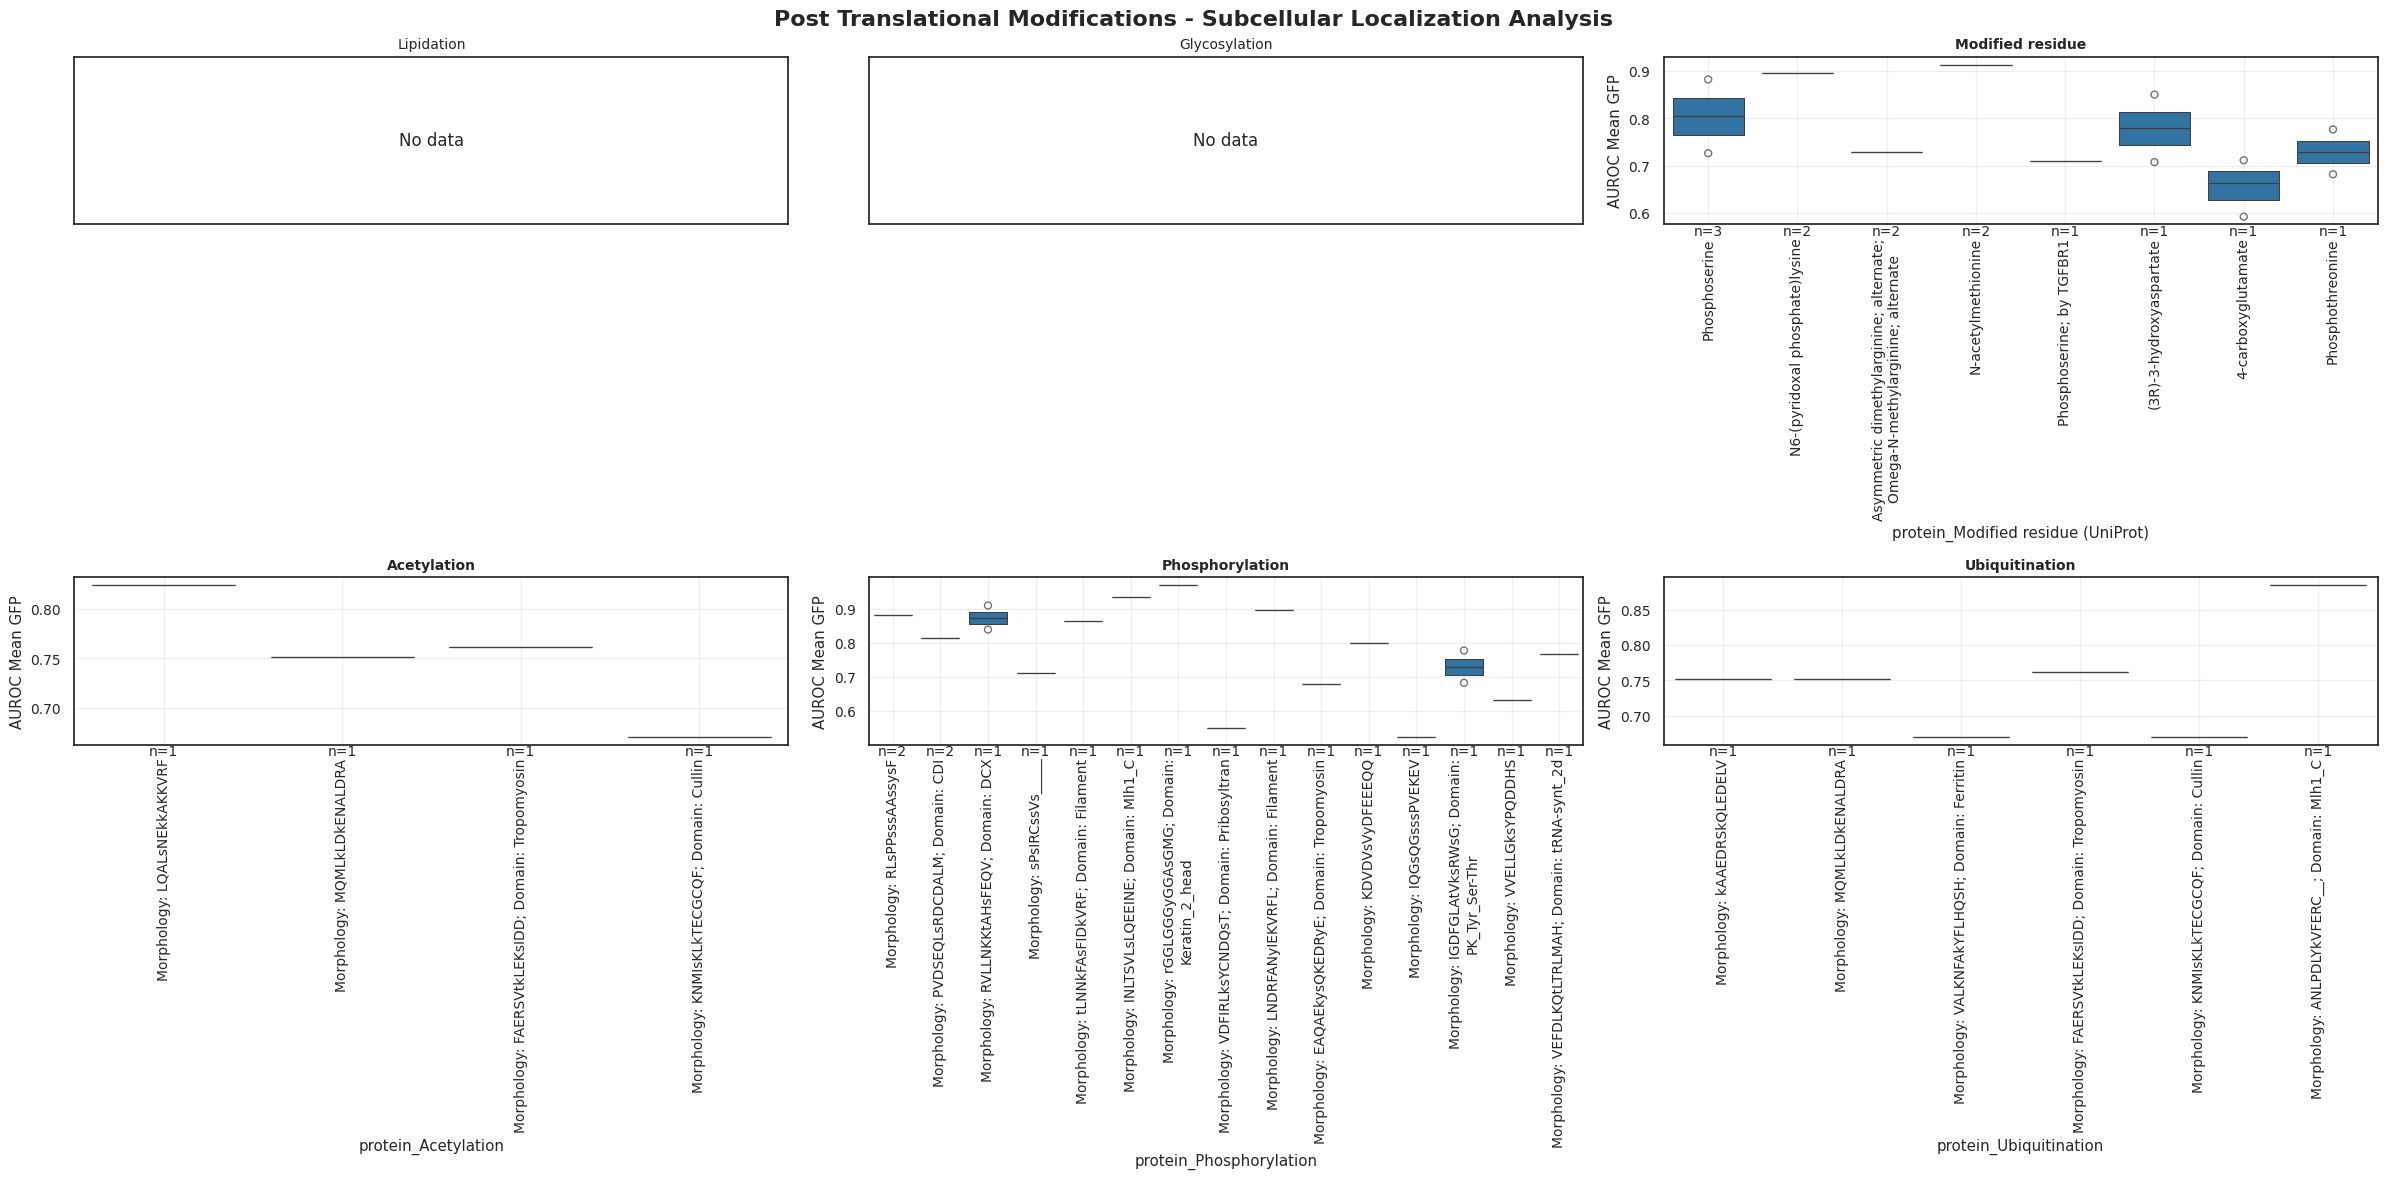


Post Translational Modifications Summary:
Features analyzed: 6
  protein_Lipidation (UniProt): None, 0 non-null values
  protein_Glycosylation (UniProt): None, 0 non-null values
  protein_Modified residue (UniProt): categorical, 13 non-null values
  protein_Acetylation: categorical, 4 non-null values
  protein_Phosphorylation: categorical, 23 non-null values
  protein_Ubiquitination: categorical, 6 non-null values

ANALYZING: Protein Domains Sites


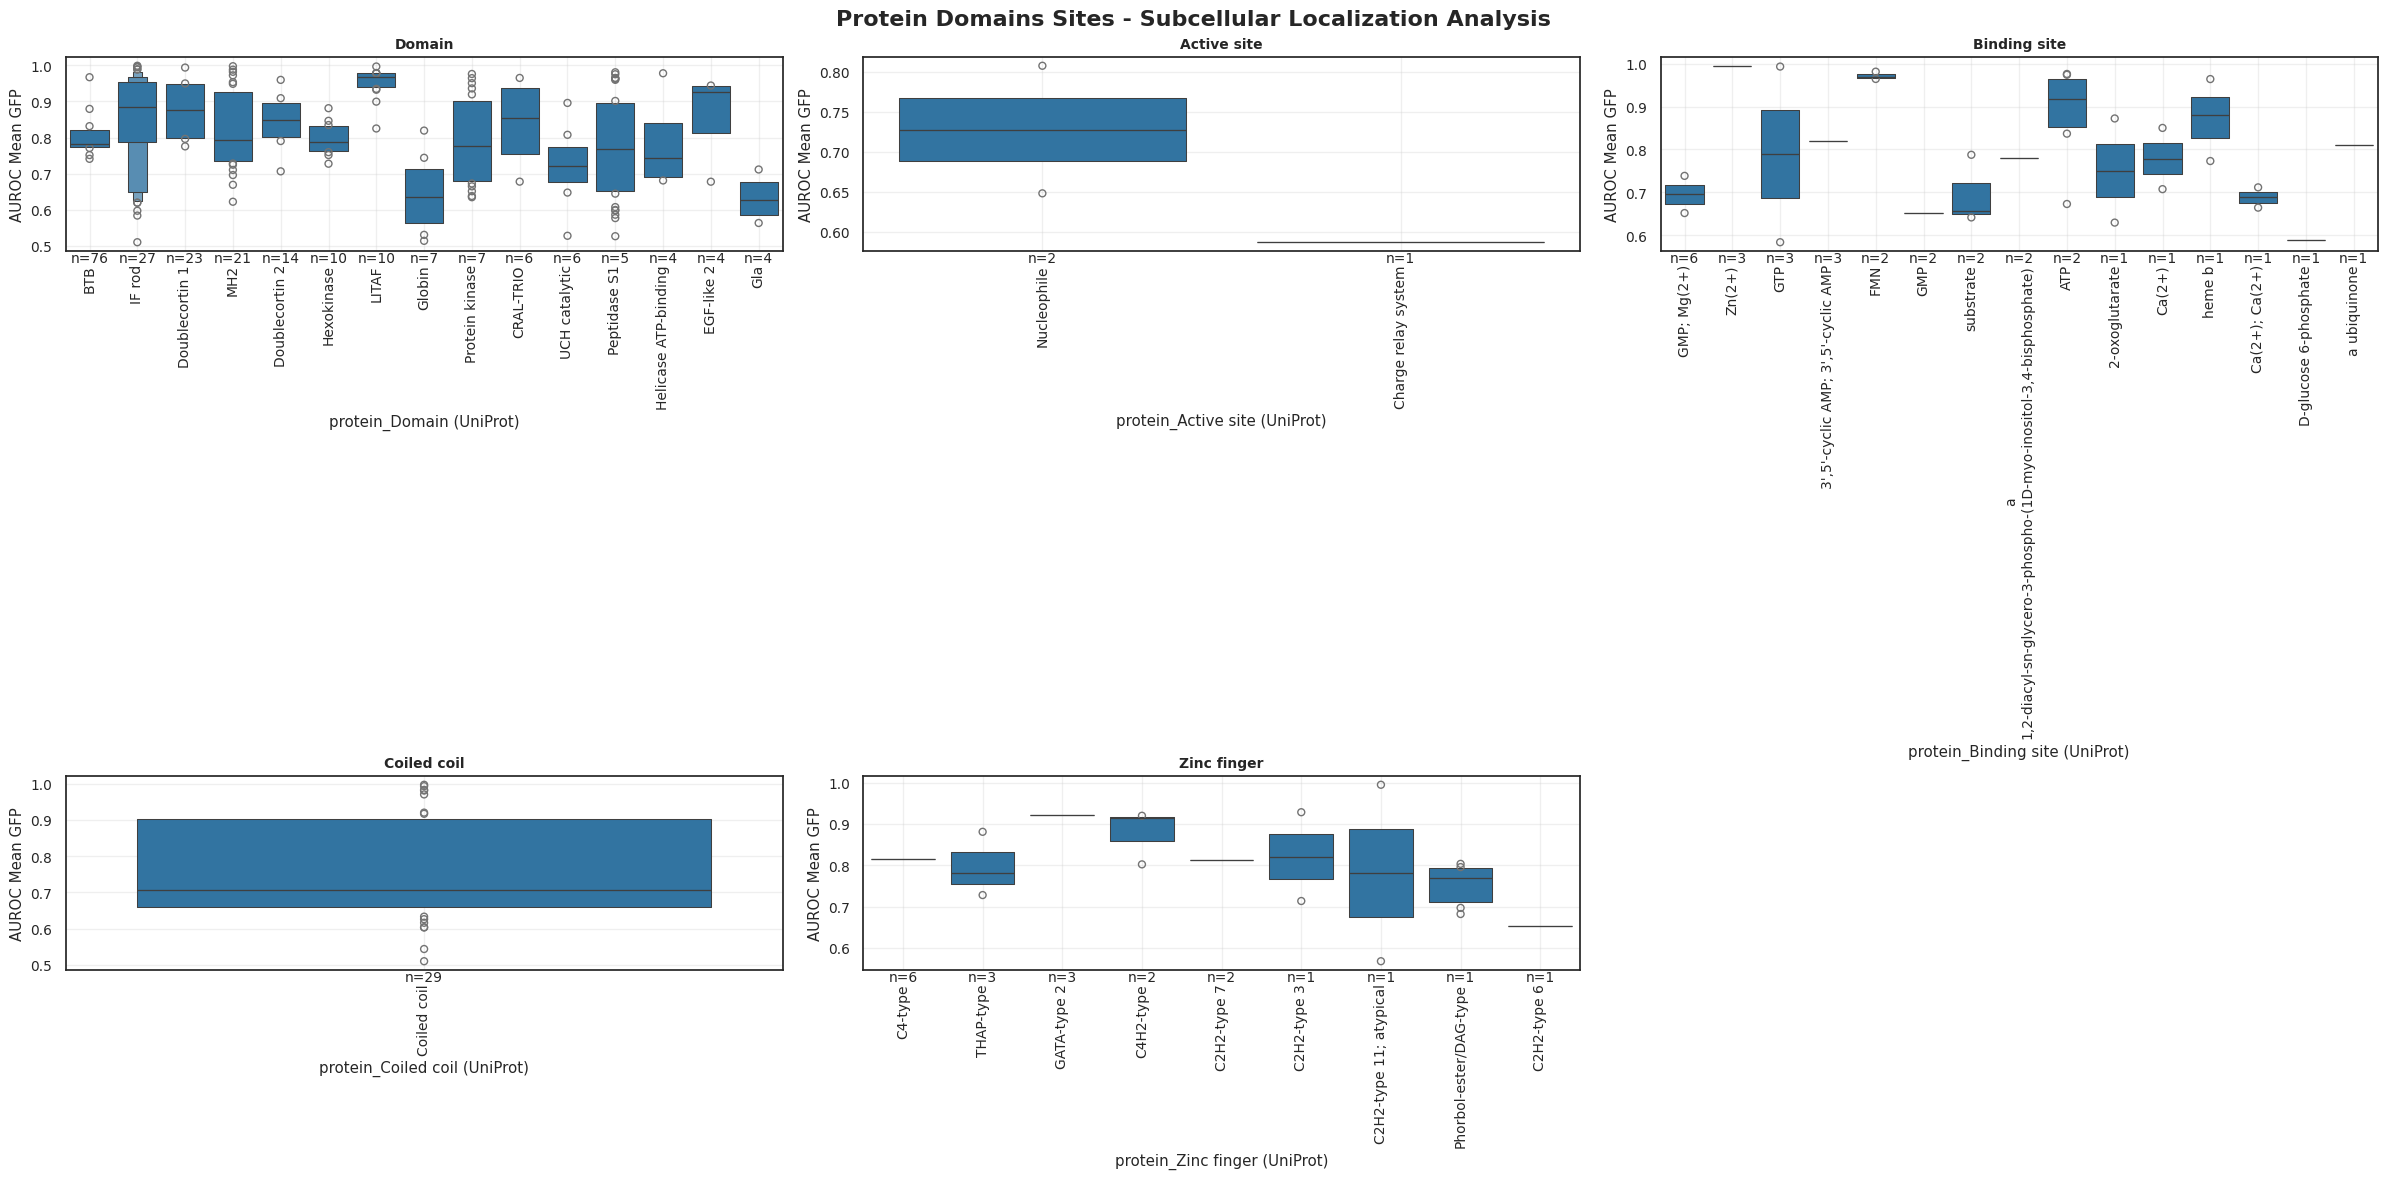


Protein Domains Sites Summary:
Features analyzed: 5
  protein_Domain (UniProt): categorical, 279 non-null values
  protein_Active site (UniProt): categorical, 3 non-null values
  protein_Binding site (UniProt): categorical, 31 non-null values
  protein_Coiled coil (UniProt): categorical, 29 non-null values
  protein_Zinc finger (UniProt): categorical, 20 non-null values


In [46]:
from matplotlib.patches import Rectangle
import warnings
warnings.filterwarnings('ignore')

# Read the data
df = imaging_summary_clinvar.to_pandas()

# Define feature categories for subcellular localization analysis
feature_categories = {
    'Signal_Sequences_Targeting': [
        'protein_Signal (UniProt)',
        'protein_Transit peptide (UniProt)', 
        'protein_Transmembrane (UniProt)',
        'protein_Topological domain (UniProt)',
        'protein_Intramembrane (UniProt)'
    ],
    
    'Nuclear_Targeting': [
        'protein_Motif (UniProt)',
        'protein_Region (UniProt)'
    ],
    
    'Structural_Context': [
        'protein_Hydropathy',
        'protein_Secondary structure (DSSP 3-state)*',
        'protein_Secondary structure (DSSP 9-state)*',
        'protein_Accessible surface area (Å²)*',
        'protein_AlphaFold confidence (pLDDT)'
    ],
    
    'Post_Translational_Modifications': [
        'protein_Lipidation (UniProt)',
        'protein_Glycosylation (UniProt)',
        'protein_Modified residue (UniProt)',
        'protein_Acetylation',
        'protein_Phosphorylation',
        'protein_Ubiquitination'
    ],
    
    'Protein_Domains_Sites': [
        'protein_Domain (UniProt)',
        'protein_Active site (UniProt)',
        'protein_Binding site (UniProt)',
        'protein_Coiled coil (UniProt)',
        'protein_Zinc finger (UniProt)'
    ]
}

def determine_feature_type(df, feature):
    """Determine if feature is categorical or continuous"""
    if feature not in df.columns:
        return None
    
    # Get non-null values
    values = df[feature].dropna()
    if len(values) == 0:
        return None
    
    # Check if numeric
    if pd.api.types.is_numeric_dtype(values):
        return 'continuous'
    else:
        return 'categorical'

        
def clean_categorical_data(series, max_categories=15):
    """Clean categorical data for plotting"""
    # Remove null values
    cleaned = series.dropna()
    
    # Get value counts
    value_counts = cleaned.value_counts()
    
    # If too many categories, keep top N
    if len(value_counts) > max_categories:
        top_categories = value_counts.head(max_categories).index
        cleaned = cleaned[cleaned.isin(top_categories)]
    
    return cleaned


def format_long_string(text, max_chars=50):
    """Format long strings with line breaks at word boundaries"""
    if len(str(text)) <= max_chars:
        return str(text)
    
    words = str(text).split()
    lines = []
    current_line = ""
    
    for word in words:
        if len(current_line) == 0:
            current_line = word
        elif len(current_line) + len(word) + 1 <= max_chars:
            current_line += " " + word
        else:
            lines.append(current_line)
            current_line = word
    
    if current_line:
        lines.append(current_line)
    
    return "\n".join(lines)


def plot_category_analysis(df, category_name, features, figsize_per_plot=(8, 6)):
    """Plot analysis for a category of features"""
    # Filter valid features
    valid_features = [f for f in features if f in df.columns]
    if not valid_features:
        print(f"No valid features found for {category_name}")
        return
    
    # Calculate subplot layout
    n_features = len(valid_features)
    n_cols = min(3, n_features)
    n_rows = (n_features + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(figsize_per_plot[0] * n_cols, figsize_per_plot[1] * n_rows))
    if n_features == 1:
        axes = [axes]
    elif n_rows == 1:
        axes = [axes] if n_features == 1 else axes
    else:
        axes = axes.flatten()
    
    fig.suptitle(f'{category_name.replace("_", " ")} - Subcellular Localization Analysis', 
                 fontsize=16, fontweight='bold', y=0.98)
    
    for i, feature in enumerate(valid_features):
        ax = axes[i]
        
        # Determine feature type
        feature_type = determine_feature_type(df, feature)
        
        if feature_type is None:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes, fontsize=12)
            ax.set_title(feature.replace('protein_', '').replace(' (UniProt)', ''), fontsize=10)
            ax.set_xticks([])
            ax.set_yticks([])
            continue
        
        try:
            if feature_type == 'categorical':
                # For categorical features: boxenplot of AUROC_Mean_GFP per category
                plot_data = df[[feature, 'AUROC_Mean_GFP']].dropna()
                if len(plot_data) == 0:
                    ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes, fontsize=12)
                    ax.set_xticks([])
                    ax.set_yticks([])
                else:
                    # Clean categorical data
                    cleaned_feature = clean_categorical_data(plot_data[feature])
                    plot_data_clean = plot_data[plot_data[feature].isin(cleaned_feature)]
                    if len(plot_data_clean) == 0:
                        ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes, fontsize=12)
                        ax.set_xticks([])
                        ax.set_yticks([])
                    else:
                        # Format long category labels
                        plot_data_clean = plot_data_clean.copy()
                        plot_data_clean[feature] = plot_data_clean[feature].apply(format_long_string)
                        
                        sns.boxenplot(data=plot_data_clean, x=feature, y='AUROC_Mean_GFP', ax=ax)
                        ax.tick_params(axis='x', rotation=90, labelsize=10)
                        ax.set_ylabel('AUROC Mean GFP')
                        
                        # Add sample sizes
                        cat_counts = plot_data_clean[feature].value_counts()
                        for j, (cat, count) in enumerate(cat_counts.items()):
                            ax.text(j, ax.get_ylim()[0]-1e-4, f'n={count}', ha='center', va='top', fontsize=10)
            
            else:  # continuous
                # For continuous features: boxenplot per Altered_95th_perc_both_batches_GFP category
                plot_data = df[[feature, 'Altered_95th_perc_both_batches_GFP']].dropna()
                
                if len(plot_data) == 0:
                    ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes, fontsize=10)
                    ax.set_xticks([])
                    ax.set_yticks([])
                else:
                    # Format long category labels
                    plot_data = plot_data.copy()
                    plot_data['Altered_95th_perc_both_batches_GFP'] = plot_data['Altered_95th_perc_both_batches_GFP'].apply(format_long_string)
                    
                    sns.boxenplot(data=plot_data, x='Altered_95th_perc_both_batches_GFP', y=feature, ax=ax)
                    ax.set_xlabel('Altered 95th Perc GFP')
                    ax.tick_params(axis='x', rotation=90, labelsize=10)
                    
                    # Add sample sizes
                    cat_counts = plot_data['Altered_95th_perc_both_batches_GFP'].value_counts()
                    for j, (cat, count) in enumerate(cat_counts.items()):
                        ax.text(j, ax.get_ylim()[0]-1e-4, f'n={count}', ha='center', va='top', fontsize=10)
    
        except Exception as e:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes, fontsize=10)
            ax.set_xticks([])
            ax.set_yticks([])
            print(f"Error plotting {feature}: {e}")
        
        # Clean up title
        clean_title = feature.replace('protein_', '').replace(' (UniProt)', '').replace('*', '')
        ax.set_title(clean_title, fontsize=10, fontweight='bold')
        ax.grid(True, alpha=0.3)
    
    # Hide empty subplots
    for i in range(len(valid_features), len(axes)):
        axes[i].set_visible(False)
    
    plt.tight_layout()
    plt.show()
    
    # Print summary statistics
    print(f"\n{category_name.replace('_', ' ')} Summary:")
    print(f"Features analyzed: {len(valid_features)}")
    
    for feature in valid_features:
        feature_type = determine_feature_type(df, feature)
        non_null_count = df[feature].notna().sum()
        print(f"  {feature}: {feature_type}, {non_null_count} non-null values")

# Print the feature categories dictionary
print("Feature Categories for Subcellular Localization Analysis:")
print("=" * 60)
for category, features in feature_categories.items():
    print(f"\n{category.replace('_', ' ')}:")
    for feature in features:
        print(f"  - {feature}")

print(f"\nDataset shape: {df.shape}")
print(f"AUROC_Mean_GFP range: {df['AUROC_Mean_GFP'].min():.3f} - {df['AUROC_Mean_GFP'].max():.3f}")
print(f"Altered_95th_perc_both_batches_GFP categories: {df['Altered_95th_perc_both_batches_GFP'].value_counts()}")

# Run analysis for each category
for category_name, features in feature_categories.items():
    print(f"\n{'='*80}")
    print(f"ANALYZING: {category_name.replace('_', ' ')}")
    print(f"{'='*80}")
    plot_category_analysis(df, category_name, features)